# 48. Correction-to-go Flow Matching for calibration

This experiment replaces the **constant analytical FM velocity target** with a **right-composed correction-to-go target**, supervising recovery from ideal, perturbed and identity correction states in SE(3) × R. The transformer, pooler, MLPBody, head and inference integrator are unchanged, preserving checkpoint compatibility.

For current accumulated correction `D`, true target `D_star`, and flow time `t < 1`:

\[v_{\xi}^{*}=\frac{\operatorname{Log}(D^{-1}D_{\star})}{1-t},\qquad v_{\tau}^{*}=\frac{\Delta\tau_{\star}-\tau}{1-t}.\]

Training uses correction-to-go velocity MSE plus optional differentiable endpoint loss. Inference always starts at identity and integrates the original velocity head. In this notebook all stochastic-specific settings are independent of full-training settings. The stochastic check has reversible model/RNG restoration; **full training and held-out testing are disabled by default**.

**Repository installation:** Copy the provided `calibration_path.py` into `src/obscalib/flow_matching/calibration_path.py`, restart the notebook kernel, then run the geometry/oracle preflight before optimizing. No other repository source replacement is needed. The uploaded notebook is the basis for datasets, augmentations and checkpoint compatibility.

**Research caveat:** off-path recovery targets assume the principal SE(3) logarithm and need extra caution close to the SO(3) branch at ±π. This is a deterministic corrective-flow experiment, not noise-conditioned diffusion.


1. Imports and project root

In [25]:
from pathlib import Path
from dataclasses import asdict, fields, is_dataclass, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository root (must contain src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.flow_matching.calibration_path import make_correction_to_go_flow_batch
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("ROOT", ROOT, "| PyTorch", torch.__version__, "| CUDA", torch.cuda.is_available())


ROOT /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch 2.7.1+cu126 | CUDA True


## 2. Independent full-run and stochastic-preflight settings


In [26]:
RUN_NAME = "kaist_pooled_calibration_fm.5_correction_to_go"
SOURCE_FM_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.4_differentiable_endpoint" / "best.pt"  # FM .4; change if your local FM4 run directory differs
SOURCE_REGRESSION_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light" / "best.pt"
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / "best.pt", RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 23456, 34567, 45678
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
MEASUREMENT_DIM = 6
WINDOW_DURATION_S, WINDOW_STRIDE_S = 5.0, 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE, NUM_WORKERS = 8, 0

# Correction-to-go fine-tuning from the trained FM .4 checkpoint; model architecture unchanged.
HEAD_LEARNING_RATE = 5e-5
BACKBONE_LEARNING_RATE = 5e-6
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
GRADIENT_ACCUMULATION_STEPS = 4  # Four parent batches per optimizer update
FLOW_PATH_NUM_POINTS = 9  # Stratified time samples in [0, max_time], always includes t=0
TRAIN_INTEGRATION_STEPS = 4  # Differentiable Lie-Euler steps (inference is unchanged)
TRAIN_INTEGRATION_METHOD = "euler"
VELOCITY_LOSS_WEIGHT = 1.0
ENDPOINT_LOSS_WEIGHT = 0.2
FULL_TRAIN_TOPOLOGY = "original"  # "original", "replace_lidar", "replace_lidar_right", "mixture"
FULL_TRAIN_REGIME = "fine"     # "fine", "coarse", "mixed"
# These settings affect FULL training and its validation only, NOT the stochastic preflight.
FULL_STATE_MODE = "mixed"           # "on_path", "off_path", "identity", "mixed"
FULL_OFF_PATH_PROBABILITY = 0.50
FULL_IDENTITY_PROBABILITY = 0.15
FULL_MAX_FLOW_TIME = 0.975
FULL_OFF_PATH_ROTATION_STD_DEG = 8.0
FULL_OFF_PATH_TRANSLATION_STD_M = 0.02
FULL_OFF_PATH_TAU_STD_S = 0.02
FULL_RANDOMIZED_INTEGRATION = True
FULL_RANDOMIZE_QUERY_TIMES = True
FULL_OBJECTIVE = dict(mode=FULL_STATE_MODE, off_path_probability=FULL_OFF_PATH_PROBABILITY,
                      identity_probability=FULL_IDENTITY_PROBABILITY, max_time=FULL_MAX_FLOW_TIME,
                      rotation_noise_std_rad=np.deg2rad(FULL_OFF_PATH_ROTATION_STD_DEG),
                      translation_noise_std_m=FULL_OFF_PATH_TRANSLATION_STD_M,
                      tau_noise_std_s=FULL_OFF_PATH_TAU_STD_S,
                      velocity_weight=VELOCITY_LOSS_WEIGHT, endpoint_weight=ENDPOINT_LOSS_WEIGHT,
                      randomized_integration=FULL_RANDOMIZED_INTEGRATION,
                      randomized_query_times=FULL_RANDOMIZE_QUERY_TIMES)
FULL_OBJECTIVE.update(
    on_policy_fraction=0.50,
    on_policy_steps=8,
    on_policy_method="midpoint",
    on_policy_max_time=0.875,
)
TRAIN_EPOCHS = 200
LR_REDUCE_STEPS, LR_REDUCE_FACTOR = 10, 0.5
MAX_TRAIN_BATCHES_PER_EPOCH = None
MAX_VAL_BATCHES_PER_EPOCH = None
REGIME_VALIDATION_BATCHES = 3
RUN_FULL_TRAINING = True
RUN_FINAL_EVALUATION = True
REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING = False

FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
RUN_INTEGRATION_ABLATION = True
ABLATION_STEPS = (1, 2, 4, 8, 16, 32)
EVAL_WINDOWS_PER_SEQUENCE = 3

# EXACT prior-corruption distribution from notebook 44.
FINE_PRIOR_PROBABILITY = 0.40
FINE_ROTATION_MAX_RAD = np.deg2rad(60.0)
FINE_ROTATION_SCALE_RAD = np.deg2rad(30.0)
FINE_TIME_OFFSET_MAX_S, FINE_TIME_OFFSET_SCALE_S = 0.500, 0.250
COARSE_ROTATION_MAX_RAD = np.deg2rad(179.0)
COARSE_TIME_OFFSET_MAX_S, COARSE_TIME_OFFSET_SCALE_S = 0.500, 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
TRUE_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_TIME_OFFSET_MAX_S = 0.030

# EXACT topology modes, frequencies and synthetic mounting policy from notebook 42.
TOPOLOGY_MODES = ("original", "replace_lidar", "replace_lidar_right")
TOPOLOGY_PROBABILITIES = (0.50, 0.25, 0.25)
TOPOLOGY_SYNTHETIC_MOUNT_MAX_DEG = 180.0
TOPOLOGY_SYNTH_GYRO_NOISE_STD = 0.0
TOPOLOGY_SYNTH_ACCEL_NOISE_STD = 0.0
EXPECTED_KEYS_BY_TOPOLOGY = {
    "original": frozenset(("imu", "lidar", "lidar_right")),
    "replace_lidar": frozenset(("imu", "imu_synth", "lidar_right")),
    "replace_lidar_right": frozenset(("imu", "lidar", "imu_synth")),
}
assert np.isclose(sum(TOPOLOGY_PROBABILITIES), 1.0) and all(p > 0 for p in TOPOLOGY_PROBABILITIES)
assert FINE_ROTATION_MAX_RAD <= COARSE_ROTATION_MAX_RAD < np.pi

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
if not SOURCE_FM_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source FM checkpoint missing: {SOURCE_FM_CHECKPOINT}; change SOURCE_FM_CHECKPOINT to your selected FM48/FM4 checkpoint.")
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Starting FM weights:", SOURCE_FM_CHECKPOINT)
print("Correction-to-go time queries:", FLOW_PATH_NUM_POINTS)
print("Topology probabilities:", dict(zip(TOPOLOGY_MODES, TOPOLOGY_PROBABILITIES)))
print("Fine/coarse:", FINE_PRIOR_PROBABILITY, 1-FINE_PRIOR_PROBABILITY, "| 60°/179°")
print("Correction-to-go + optional differentiable endpoint; full training:", RUN_FULL_TRAINING)


Starting FM weights: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.4_differentiable_endpoint/best.pt
Correction-to-go time queries: 9
Topology probabilities: {'original': 0.5, 'replace_lidar': 0.25, 'replace_lidar_right': 0.25}
Fine/coarse: 0.4 0.6 | 60°/179°
Correction-to-go + optional differentiable endpoint; full training: True


3. KAIST datasets and unchanged rig references

In [27]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

train 2006 windows
validation 418 windows
test 699 windows


4. Topology-aware physical augmentation and notebook-44 priors

Each physical window first chooses exactly one topology. Homogeneous examples are grouped so the augmentation pipeline can change stream/calibration schemas, then each group draws its own fine/coarse mask per physical example. We never perturb an already-updated calibration as the truth source.

The topology pipeline is taken from notebook 42; the fine/coarse priors and target semantics are taken from notebook 44. Common-frame rotation stays disabled to isolate topology effects.

In [28]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

def topology_config_for_mode(mode: str) -> SensorTopologyAugmentationConfig:
    if mode not in TOPOLOGY_MODES:
        raise ValueError(mode)
    return SensorTopologyAugmentationConfig(
        enabled=(mode != "original"), replacement_probability=1.0,
        replace_first_lidar_probability=1.0 if mode == "replace_lidar" else 0.0,
        maximum_mount_rotation_deg=TOPOLOGY_SYNTHETIC_MOUNT_MAX_DEG,
        synthetic_gyro_noise_std=TOPOLOGY_SYNTH_GYRO_NOISE_STD,
        synthetic_accel_noise_std=TOPOLOGY_SYNTH_ACCEL_NOISE_STD,
    )

physical_augmenters = {
    mode: AugmentationPipeline(replace(true_calibration_config, sensor_topology=topology_config_for_mode(mode)))
    for mode in TOPOLOGY_MODES
}

fine_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
coarse_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=COARSE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

# Probability that each calibration receives the ONE prior fault in a physical window.
# Keep original KAIST unchanged; emphasize the remaining real LiDAR in 2-IMU/1-LiDAR cases.
FAULT_KEY_WEIGHTS = {
    frozenset(("imu", "lidar", "lidar_right")): {"imu": 1.0, "lidar": 1.0, "lidar_right": 1.0},
    frozenset(("imu", "imu_synth", "lidar_right")): {"imu": 0.20, "imu_synth": 0.20, "lidar_right": 0.60},
    frozenset(("imu", "lidar", "imu_synth")): {"imu": 0.20, "lidar": 0.60, "imu_synth": 0.20},
}

def sample_fine_coarse_deltas(true_states, generator: torch.Generator, regime: str = "mixed"):
    if regime not in {"mixed", "fine", "coarse"}:
        raise ValueError(regime)

    keys = tuple(true_states)
    probability_by_key = FAULT_KEY_WEIGHTS.get(frozenset(keys))
    if probability_by_key is None:
        raise ValueError(f"No fault-selection weights for calibration keys {keys}")

    template = next(iter(true_states.values())).transform
    n = len(template)
    weights = torch.tensor([probability_by_key[key] for key in keys], device=template.device, dtype=torch.float32)
    weights = weights / weights.sum()
    selected_key_indices = torch.multinomial(weights, n, replacement=True, generator=generator)

    if regime == "mixed":
        fine_mask = torch.rand(n, device=template.device, generator=generator) < FINE_PRIOR_PROBABILITY
    else:
        fine_mask = torch.full((n,), regime == "fine", device=template.device, dtype=torch.bool)

    # Reuse the existing perturbers on single-key dictionaries. This preserves their
    # exact Student-t/uniform SO(3) and tau distributions while controlling key choice.
    xi, tau = {}, {}
    for key_index, key in enumerate(keys):
        singleton = {key: true_states[key]}
        if regime != "coarse":
            _, fine_xi, fine_tau = fine_prior_perturber(singleton, generator=generator)
        if regime != "fine":
            _, coarse_xi, coarse_tau = coarse_prior_perturber(singleton, generator=generator)

        if regime == "fine":
            chosen_xi, chosen_tau = fine_xi[key], fine_tau[key]
        elif regime == "coarse":
            chosen_xi, chosen_tau = coarse_xi[key], coarse_tau[key]
        else:
            chosen_xi = torch.where(fine_mask[:, None], fine_xi[key], coarse_xi[key])
            chosen_tau = torch.where(fine_mask[:, None], fine_tau[key], coarse_tau[key])

        selected = (selected_key_indices == key_index)[:, None]
        xi[key] = torch.where(selected, chosen_xi, torch.zeros_like(chosen_xi))
        tau[key] = torch.where(selected, chosen_tau, torch.zeros_like(chosen_tau))

    return xi, tau, fine_mask

@torch.no_grad()
def augment_topology_window(base_window: WindowBatch, generator: torch.Generator, *, topology: str, regime: str = "mixed") -> WindowBatch:
    if topology not in TOPOLOGY_MODES:
        raise ValueError(topology)
    physical = physical_augmenters[topology](base_window, generator=generator).augmented_window
    truth_states = physical.current_calibration
    assert frozenset(truth_states) == EXPECTED_KEYS_BY_TOPOLOGY[topology], (topology, tuple(truth_states))
    xi, tau, _ = sample_fine_coarse_deltas(truth_states, generator, regime=regime)
    return clone_with_current_calibration(physical, apply_prior_perturbation(truth_states, xi, tau))

def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Expected truth targets after topology/true-calibration augmentation")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Missing correction truth for {key}")
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau

print("Physical pipeline:", {name: p.config.sensor_topology for name, p in physical_augmenters.items()})
print("Unchanged fine/coarse priors:", fine_prior_config, coarse_prior_config)

Physical pipeline: {'original': SensorTopologyAugmentationConfig(enabled=False, replacement_probability=1.0, replace_first_lidar_probability=0.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_right'), synthetic_calibration_key='imu_synth', synthetic_gyro_stream='gyro_synth', synthetic_accel_stream='accel_synth', maximum_mount_rotation_deg=180.0, synthetic_gyro_noise_std=0.0, synthetic_accel_noise_std=0.0), 'replace_lidar': SensorTopologyAugmentationConfig(enabled=True, replacement_probability=1.0, replace_first_lidar_probability=1.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_right'), synthetic_calibration_key='imu_synth', synthetic_gyro_stream='gyro_synth', synthetic_accel_stream='accel_synth', maximum_mount_rotation_deg=180.0, synthetic_gyro_noise_std=0.0, synthetic_accel_noise_std=0.0), 'replace_lidar_right': SensorTopologyAugmentationConfig(enabled=True, replacement_probability=1.0, replace_first_lidar_probability=0.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_ri

## 5. Per-example topology mixture and schema-safe batch splitting
The original KAIST WindowBatch has one schema. As in notebook 42, randomly choose a topology per physical example and process each set as a separate subbatch. Weight each loss by subbatch_size / original_batch_size before backward, so rare topologies are neither lost nor overcounted. The dataset_indices metadata follows the selection as well.

In [29]:
def topology_slice_batch(window: WindowBatch, positions: torch.Tensor) -> WindowBatch:
    n = len(next(iter(window.current_calibration.values())).transform)
    if positions.numel() == 0:
        raise ValueError("Cannot create an empty topology group")
    positions_cpu = positions.detach().cpu().tolist()
    original_indices = window.dataset_indices
    if isinstance(original_indices, torch.Tensor):
        selected_indices = original_indices.index_select(0, positions.to(device=original_indices.device))
    elif original_indices is not None and hasattr(original_indices, "__len__") and len(original_indices) == n:
        selected = [original_indices[i] for i in positions_cpu]
        selected_indices = tuple(selected) if isinstance(original_indices, tuple) else selected
    else:
        selected_indices = original_indices

    def select(item):
        if isinstance(item, torch.Tensor) and item.ndim > 0 and item.shape[0] == n:
            return item.index_select(0, positions.to(device=item.device))
        if is_dataclass(item) and not isinstance(item, type):
            updates = {field.name: (selected_indices if isinstance(item, WindowBatch) and field.name == "dataset_indices" else select(getattr(item, field.name))) for field in fields(item) if field.init}
            return replace(item, **updates)
        if isinstance(item, dict):
            return {key: select(value) for key, value in item.items()}
        return item

    return select(window)

def topology_groups(base_window: WindowBatch, generator: torch.Generator, mode: str = "mixture"):
    sample_transform = next(iter(base_window.current_calibration.values())).transform
    n = len(sample_transform)
    if mode == "mixture":
        drawn = torch.rand(n, device=sample_transform.device, generator=generator)
        ids = torch.where(drawn < TOPOLOGY_PROBABILITIES[0], 0, torch.where(drawn < sum(TOPOLOGY_PROBABILITIES[:2]), 1, 2))
    elif mode in TOPOLOGY_MODES:
        ids = torch.full((n,), TOPOLOGY_MODES.index(mode), device=sample_transform.device, dtype=torch.long)
    else:
        raise ValueError(mode)
    return [(name, topology_slice_batch(base_window, positions)) for i, name in enumerate(TOPOLOGY_MODES) if (positions := torch.nonzero(ids == i, as_tuple=False).flatten()).numel()]

# Keep the original input batch intact: topology grouping must be a partition of physical examples.
test_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
groups = topology_groups(test_base, augmentation_generator(TRAIN_AUG_SEED + 18))
assert sum(len(next(iter(w.current_calibration.values())).transform) for _, w in groups) == len(next(iter(test_base.current_calibration.values())).transform)
for mode, group in groups:
    print("Partition", mode, "n=", len(next(iter(group.current_calibration.values())).transform))

Partition original n= 3
Partition replace_lidar n= 1
Partition replace_lidar_right n= 4


## 6. Load pretrained FM .4 without changing the model architecture


In [30]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.freeze_feature_extractor(False)
fm_loss_weights = flow_config.loss.to_loss_weights()

for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body, fm_model.head):
    assert all(p.requires_grad for p in module.parameters())
print("FM checkpoint loaded:", SOURCE_FM_CHECKPOINT)
print("FM parameters:", sum(p.numel() for p in fm_model.parameters()), "trainable:", sum(p.numel() for p in fm_model.parameters() if p.requires_grad))

FM checkpoint loaded: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.4_differentiable_endpoint/best.pt
FM parameters: 2555399 trainable: 2555399


## 7. Corrective velocity supervision and differentiable endpoint loss


In [31]:
class _CapturedTokens(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens = None
        self.context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.tokens = tokens
        self.context = calibration_context
        raise _CapturedTokens()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
capture_model = _TokenCaptureModel()

def tokenize_window(window: WindowBatch):
    # Topology-dependent calibration key set/order MUST be decided after augmentation.
    calibration_keys = tuple(window.current_calibration)
    step = WindowStep(geometry_processor=geometry_processor, tokenizer=Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=calibration_keys), model=capture_model, calibration_updater=calibration_updater)
    capture_model.tokens = None
    capture_model.context = None
    try:
        step(window)
    except _CapturedTokens:
        pass
    if capture_model.tokens is None:
        raise RuntimeError("WindowStep did not call model: failed to capture tokens")
    if tuple(capture_model.tokens.calibration_keys) != calibration_keys:
        raise AssertionError((calibration_keys, capture_model.tokens.calibration_keys))
    return capture_model.tokens, capture_model.context

def flow_supervision(window: WindowBatch, *, generator: torch.Generator, model=None):
    model = fm_model if model is None else model
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    output = model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=generator)
    loss = calibration_velocity_loss(output.predicted_velocity, output.flow_batch.target_velocity, weights=fm_loss_weights)
    return loss, output

@torch.no_grad()
def model_predictions(model, window, steps=FM_INTEGRATION_STEPS):
    tokens, context = tokenize_window(window)
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, context, num_steps=steps, method=FM_INTEGRATION_METHOD)
    return model(tokens, context)

from dataclasses import dataclass
from obscalib.flow_matching.lie_integrator import integrate_calibration_flow, CalibrationFlowResult

@dataclass
class JointFMEndpointLoss:
    total: torch.Tensor
    velocity: object
    endpoint: torch.Tensor
    endpoint_rotation: torch.Tensor
    endpoint_translation: torch.Tensor
    endpoint_tau: torch.Tensor
    lidar_active_rotation_deg: torch.Tensor
    lidar_healthy_rotation_deg: torch.Tensor

    def detached_metrics(self):
        metrics = self.velocity.detached_metrics()
        metrics.update({
            "loss_combined_total": float(self.total.detach()),
            "loss_endpoint_total": float(self.endpoint.detach()),
            "loss_endpoint_rotation": float(self.endpoint_rotation.detach()),
            "loss_endpoint_translation": float(self.endpoint_translation.detach()),
            "loss_endpoint_time_offset": float(self.endpoint_tau.detach()),
            "endpoint_lidar_active_rotation_deg": float(self.lidar_active_rotation_deg.detach()),
            "endpoint_lidar_healthy_rotation_deg": float(self.lidar_healthy_rotation_deg.detach()),
        })
        return metrics


def endpoint_loss_from_integration(window, flow_result, keys, target_xi, *, weights):
    """Physical corrected extrinsics and clocks; no detach anywhere on predicted path."""
    current = torch.stack([window.current_calibration[key].transform for key in keys], dim=1)
    desired = torch.stack([window.targets[key].next_transform for key in keys], dim=1)
    current_tau = torch.stack([window.current_calibration[key].time_offset for key in keys], dim=1)
    desired_tau = torch.stack([window.targets[key].next_time_offset for key in keys], dim=1)
    corrected = flow_result.correction_transform @ current
    predicted_tau = current_tau + flow_result.delta_tau

    # SO(3) geodesic angle is stable near identity and bounded by pi.
    residual_rotation = desired[..., :3, :3] @ corrected[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((
        residual_rotation[..., 2, 1] - residual_rotation[..., 1, 2],
        residual_rotation[..., 0, 2] - residual_rotation[..., 2, 0],
        residual_rotation[..., 1, 0] - residual_rotation[..., 0, 1],
    ), dim=-1)
    sin_angle = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_angle = 0.5 * (residual_rotation.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    rotation_angle = torch.atan2(sin_angle, cos_angle)
    translation_error = corrected[..., :3, 3] - desired[..., :3, 3]
    tau_error = predicted_tau - desired_tau

    rotation_loss = (rotation_angle / weights.rotation_scale_rad).square().mean()
    translation_loss = (translation_error / weights.translation_scale_m).square().mean()
    tau_loss = (tau_error / weights.time_offset_scale_s).square().mean()
    combined = weights.rotation_weight * rotation_loss + weights.translation_weight * translation_loss + weights.time_offset_weight * tau_loss

    active_angles, healthy_angles = [], []
    for index, key in enumerate(keys):
        if key.startswith("lidar"):
            active_mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
            if bool(active_mask.any()): active_angles.append(torch.rad2deg(rotation_angle[:, index][active_mask]))
            if bool((~active_mask).any()): healthy_angles.append(torch.rad2deg(rotation_angle[:, index][~active_mask]))
    nan_metric = rotation_angle.detach().new_tensor(float("nan"))
    active = torch.cat(active_angles).mean() if active_angles else nan_metric
    healthy = torch.cat(healthy_angles).mean() if healthy_angles else nan_metric
    return combined, rotation_loss, translation_loss, tau_loss, active, healthy


def stratified_flow_grid(reference, num_points, max_time, *, generator=None, randomized=True):
    """Return time queries in [0, max_time], always supervising t=0.

    Evaluation uses a fixed grid; training samples one time in every interior
    stratum rather than learning only a handful of fixed interpolation times.
    """
    if num_points < 2:
        raise ValueError("At least two time points required")
    if randomized:
        increments = (torch.arange(1, num_points, device=reference.device, dtype=reference.dtype) +
                      torch.rand(num_points - 1, device=reference.device, dtype=reference.dtype, generator=generator))
        return torch.cat((reference.new_zeros(1), max_time * increments / num_points))
    return torch.linspace(0, max_time, num_points, device=reference.device, dtype=reference.dtype)


def integrate_training_correction(model, shared, stacked_context, *, generator=None, randomized=True):
    """Train with right-composed Lie-Euler and optionally jittered step boundaries.

    Uses the same update rule as integrate_calibration_flow, with actual dt_k.
    Jitter is disabled in deterministic validation; inference remains unchanged.
    """
    if not randomized:
        return model.integrate_from_features(shared, stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    if TRAIN_INTEGRATION_METHOD != "euler":
        raise ValueError("Randomized training intervals currently require Lie-Euler")
    num_steps = TRAIN_INTEGRATION_STEPS
    b, c, _ = shared.shape
    grid = torch.linspace(0, 1, num_steps + 1, device=shared.device, dtype=shared.dtype)
    if num_steps > 1:
        perturb = (torch.rand(num_steps - 1, device=shared.device, dtype=shared.dtype, generator=generator) - 0.5) / num_steps
        grid = torch.cat((grid[:1], grid[1:-1] + perturb, grid[-1:]))
    D = torch.eye(4, dtype=shared.dtype, device=shared.device).expand(b, c, 4, 4).clone()
    tau = shared.new_zeros(b, c, 1)
    for k in range(num_steps):
        dt = grid[k + 1] - grid[k]
        xi = shared.new_zeros(b, c, 6) if k == 0 else se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6)
        t = grid[k].expand(b, c, 1)
        v = model.velocity_from_features(shared, xi, tau, t, stacked_context)
        D = D @ se3_exp((dt * v[..., :6]).reshape(-1, 6)).reshape(b, c, 4, 4)
        tau = tau + dt * v[..., 6:]
    return CalibrationFlowResult(se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6), tau, D)


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Correction-to-go velocity MSE and optional differentiable endpoint loss.

    Encode each physical window ONCE and share features over all correction
    queries and integration steps. Targets have no gradients; the predicted
    field retains gradients through all model components.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)
    batch_size, num_calibrations, feature_dim = shared.shape
    num_points = FLOW_PATH_NUM_POINTS
    grid = stratified_flow_grid(shared, num_points, objective["max_time"], generator=generator, randomized=model.training and objective["randomized_query_times"])
    times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)
    with torch.no_grad():
        path_batch = make_correction_to_go_flow_batch(
            delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
            delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
            time=times, mode=objective["mode"],
            off_path_probability=objective["off_path_probability"],
            identity_probability=objective["identity_probability"],
            rotation_noise_std_rad=objective["rotation_noise_std_rad"],
            translation_noise_std_m=objective["translation_noise_std_m"],
            tau_noise_std_s=objective["tau_noise_std_s"],
            max_time=objective["max_time"], generator=generator,
        )
    repeated_shared = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, feature_dim)
    repeated_context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])
    predicted = model.velocity_from_features(
        repeated_shared,
        path_batch.correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        path_batch.correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        path_batch.time.reshape(num_points * batch_size, num_calibrations, 1),
        repeated_context,
    ).reshape(num_points, batch_size, num_calibrations, 7)
    # Active rotation is defined by the original corrupted sensor, NOT by the
    # off-path recovery velocity of an otherwise healthy calibration.
    active_mask = (torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad)
    active_mask = active_mask.unsqueeze(0).expand(num_points, -1, -1)
    velocity = calibration_velocity_loss(predicted, path_batch.target_velocity, weights=fm_loss_weights, active_rotation_mask=active_mask)

    # The field integrates along its own trajectory, not the teacher path.
    # No torch.no_grad here: train-time endpoint loss must reach the head and backbone.
    result = integrate_training_correction(model, shared, stacked_context, generator=generator,
        randomized=model.training and objective["randomized_integration"])
    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy = endpoint_loss_from_integration(window, result, keys, target_xi, weights=fm_loss_weights)
    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")
    return JointFMEndpointLoss(total, velocity, endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy), result


from obscalib.flow_matching.loss import CalibrationFlowLoss


@dataclass
class OnPolicyJointFMEndpointLoss(JointFMEndpointLoss):
    analytical_velocity_total: torch.Tensor
    on_policy_velocity_total: torch.Tensor

    def detached_metrics(self):
        metrics = super().detached_metrics()
        metrics["loss_fm_analytical_total"] = float(self.analytical_velocity_total.detach())
        metrics["loss_fm_on_policy_total"] = float(self.on_policy_velocity_total.detach())
        return metrics


def _velocity_at_flow_states(model, shared, stacked_context, correction_xi, correction_tau, times):
    """Evaluate the trainable velocity head over multiple correction states."""
    num_points, batch_size, num_calibrations, _ = correction_xi.shape
    hidden_dim = shared.shape[-1]

    features = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, hidden_dim)
    context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])

    predicted = model.velocity_from_features(
        features,
        correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        times.reshape(num_points * batch_size, num_calibrations, 1),
        context,
    )
    return predicted.reshape(num_points, batch_size, num_calibrations, 7)


def _rollout_correction_to_go_states(model, shared, stacked_context, delta_xi, delta_tau, *, num_steps, max_time, method):
    """Integrate the current model without autograd and supervise its visited states."""
    if not (0.0 <= max_time < 1.0):
        raise ValueError("on_policy_max_time must be in [0, 1).")
    if num_steps < 1:
        raise ValueError("on_policy_steps must be positive.")

    with torch.no_grad():
        context = None if stacked_context is None else stacked_context.detach()
        result = model.integrate_from_features(
            shared.detach(), context,
            num_steps=num_steps, method=method, record_trajectory=True,
        )

        states = tuple(state for state in result.trajectory if state.time <= max_time + 1e-7)
        if not states or abs(states[0].time) > 1e-7:
            raise RuntimeError("Rollout trajectory must begin at identity.")

        num_points = len(states)
        batch_size, num_calibrations, _ = delta_xi.shape

        D = torch.stack([state.correction_transform for state in states], dim=0)
        tau = torch.stack([state.correction_tau for state in states], dim=0)
        times = delta_tau.new_tensor([state.time for state in states]).view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        target_D = se3_exp(delta_xi.reshape(-1, 6)).reshape(batch_size, num_calibrations, 4, 4)
        remaining_D = torch.linalg.solve(D, target_D.unsqueeze(0).expand_as(D))
        remaining_xi = se3_log(remaining_D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        remaining_time = 1.0 - times
        target_velocity = torch.cat(
            (remaining_xi / remaining_time, (delta_tau.unsqueeze(0) - tau) / remaining_time),
            dim=-1,
        )
        correction_xi = se3_log(D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        if not bool(torch.isfinite(target_velocity).all()):
            raise FloatingPointError("Nonfinite on-policy correction-to-go target.")

        return correction_xi, tau, times, target_velocity


def _mix_calibration_velocity_losses(analytical, on_policy, fraction):
    """Retain the existing CalibrationFlowLoss interface and metrics."""
    a, b = 1.0 - fraction, fraction
    return CalibrationFlowLoss(
        total=a * analytical.total + b * on_policy.total,
        rotation=a * analytical.rotation + b * on_policy.rotation,
        translation=a * analytical.translation + b * on_policy.translation,
        time_offset=a * analytical.time_offset + b * on_policy.time_offset,
        active_rotation=a * analytical.active_rotation + b * on_policy.active_rotation,
        num_active_rotations=analytical.num_active_rotations + on_policy.num_active_rotations,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Analytical CTG + detached on-policy CTG + differentiable endpoint loss."""
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    # Compute sensor features ONCE. Gradients through these features are retained.
    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Original analytical correction-to-go supervision
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"], generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )
        analytical_loss = calibration_velocity_loss(
            predicted, path.target_velocity,
            weights=fm_loss_weights,
            active_rotation_mask=active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. Generate detached states from model's OWN trajectory
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        # This forward pass DOES retain gradients through all neural components.
        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = calibration_velocity_loss(
            rollout_predicted, rollout_target,
            weights=fm_loss_weights,
            active_rotation_mask=active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine both velocity objectives
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Original differentiable 4-step endpoint objective
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite on-policy joint loss.")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )
    return losses, result


In [32]:

def remaining_displacement_velocity_loss(predicted, target, times, active_mask):
    """Time-weighted CTG loss, with branch-wise weight normalization.

    The target remains velocity; multiplying BOTH arguments by remaining time
    penalizes predicted remaining displacement without changing the pointwise optimum.
    """
    if predicted.shape != target.shape or times.shape != predicted.shape[:-1] + (1,):
        raise ValueError("Inconsistent predicted, target, or time shapes")

    remaining = 1.0 - times
    if bool((remaining <= 0).any()):
        raise ValueError("Correction-to-go supervision requires t < 1")

    # Keep the mean squared time weight equal to 1 for each branch.
    scale = remaining / remaining.square().mean().sqrt().clamp_min(1e-8)

    return calibration_velocity_loss(
        predicted * scale,
        target * scale,
        weights=fm_loss_weights,
        active_rotation_mask=active_mask,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Normalized remaining-displacement supervision on analytical and rollout states.

    Sensor features are encoded once. On-policy trajectory generation is detached,
    but supervised velocity predictions retain gradients through all model blocks.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Analytical CTG supervision, up to t=0.975
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"],
            generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )

        analytical_loss = remaining_displacement_velocity_loss(
            predicted,
            path.target_velocity,
            path.time,
            active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. On-policy CTG supervision, up to t=0.875
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = remaining_displacement_velocity_loss(
            rollout_predicted,
            rollout_target,
            rollout_times,
            active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine remaining-displacement losses
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Differentiable endpoint loss, unchanged
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint

    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )

    return losses, result


## 8. Topology semantics, target ordering, and full-backbone gradient preflight
Smoke-test all three topology modes individually. This checks synthetic-key routing in both tokenization and flow supervision, including target-velocity ordering. After that, verify gradients propagate into transformer, pooler, MLPBody and FM head. No optimizer step is taken.

In [33]:
for mode_idx, mode in enumerate(TOPOLOGY_MODES):
    window = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 51 + mode_idx), topology=mode, regime="mixed")
    target_xi, target_tau = correction_targets(window)
    tokens, context = tokenize_window(window)
    assert frozenset(tokens.calibration_keys) == EXPECTED_KEYS_BY_TOPOLOGY[mode]
    assert tokens.x.shape[-1] == 8
    with torch.no_grad():
        result = fm_model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=augmentation_generator(TRAIN_AUG_SEED + 110 + mode_idx))
    assert result.predicted_velocity.shape == (len(tokens.x), len(tokens.calibration_keys), 7)
    torch.testing.assert_close(result.flow_batch.target_velocity[..., :6], torch.stack([target_xi[k] for k in tokens.calibration_keys], dim=1))
    torch.testing.assert_close(result.flow_batch.target_velocity[..., 6:], torch.stack([target_tau[k] for k in tokens.calibration_keys], dim=1))
    print(f"{mode:22s} {tuple(tokens.x.shape)} calibration_keys={tuple(tokens.calibration_keys)}: PASS")

fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_case = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 200), topology="replace_lidar", regime="coarse")
grad_losses, _ = joint_flow_endpoint_supervision(grad_case, generator=augmentation_generator(TRAIN_AUG_SEED + 201))
grad_losses.velocity.total.backward()
for block_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    gradients = [p.grad for p in getattr(fm_model, block_name).parameters() if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients), block_name
    print(f"{block_name:20s} gradient norm={sum(g.square().sum().item() for g in gradients)**0.5:.4g}")
fm_model.zero_grad(set_to_none=True)
print("Dynamic topology and CORRECTION-TO-GO velocity gradient preflight: PASS")


original               (8, 1098, 8) calibration_keys=('imu', 'lidar', 'lidar_right'): PASS
replace_lidar          (8, 2049, 8) calibration_keys=('imu', 'imu_synth', 'lidar_right'): PASS
replace_lidar_right    (8, 2049, 8) calibration_keys=('imu', 'lidar', 'imu_synth'): PASS
transformer_encoder  gradient norm=499.6
pooler               gradient norm=109.9
mlp_body             gradient norm=368.7
head                 gradient norm=541.8
Dynamic topology and CORRECTION-TO-GO velocity gradient preflight: PASS


## 8a. Required oracle integration and endpoint-gradient preflight
Oracle constant velocities must reproduce physical target calibrations using the repository integrator. Then backpropagate endpoint-only loss and verify nonzero finite gradients reach all four blocks. These checks run before stochastic/full training and leave the optimizer untouched.

In [34]:
# Oracle Lie integration: constant true velocity must recover every physical calibration.
for mode_idx, mode in enumerate(TOPOLOGY_MODES):
    example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 800 + mode_idx), topology=mode, regime="fine")
    truth_xi, truth_tau = correction_targets(example)
    keys = tuple(example.current_calibration)
    target_vel = torch.stack([torch.cat((truth_xi[key], truth_tau[key]), dim=-1) for key in keys], dim=1)
    reference = target_vel.new_zeros(*target_vel.shape[:-1], 8)
    oracle = integrate_calibration_flow(lambda xi, tau, t: target_vel, reference, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    for j, key in enumerate(keys):
        T_corrected = oracle.correction_transform[:, j] @ example.current_calibration[key].transform
        T_target = example.targets[key].next_transform
        angle = T_target[:, :3, :3] @ T_corrected[:, :3, :3].transpose(-1, -2)
        residual_angle = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(torch.stack((angle[:, 2, 1]-angle[:, 1, 2], angle[:, 0, 2]-angle[:, 2, 0], angle[:, 1, 0]-angle[:, 0, 1]), dim=-1), dim=-1), 0.5 * (angle.diagonal(dim1=-2, dim2=-1).sum(dim=-1)-1)))
        assert float(residual_angle.max()) < 0.05, (mode, key, residual_angle)
        assert float((T_corrected[:, :3, 3] - T_target[:, :3, 3]).abs().max()) < 5e-4, (mode, key, "translation")
        tau_updated = example.current_calibration[key].time_offset + oracle.delta_tau[:, j]
        torch.testing.assert_close(tau_updated, example.targets[key].next_time_offset, atol=5e-5, rtol=1e-5)
    print(mode, "oracle physical SE(3) and tau integration: PASS")

# Endpoint objective alone must backpropagate through the 4-step solver and backbone.
fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 9876), topology="replace_lidar_right", regime="fine")
with torch.no_grad():
    grad_tokens, grad_context = tokenize_window(grad_example)
    grad_targets, _ = correction_targets(grad_example)
shared, stacked_context = fm_model.encode_calibration_features(grad_tokens, grad_context)
flow = integrate_training_correction(fm_model, shared, stacked_context, generator=augmentation_generator(TRAIN_AUG_SEED + 9880), randomized=False)
endpoint_only, *_ = endpoint_loss_from_integration(grad_example, flow, tuple(grad_tokens.calibration_keys), grad_targets, weights=fm_loss_weights)
assert torch.isfinite(endpoint_only), endpoint_only
endpoint_only.backward()
for component_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    grads = [p.grad for p in getattr(fm_model, component_name).parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(bool(torch.isfinite(g).all()) for g in grads), component_name
    grad_norm = torch.sqrt(sum(g.detach().square().sum() for g in grads)).item()
    assert grad_norm > 0, (component_name, grad_norm)
    print(component_name, "endpoint-only grad norm", f"{grad_norm:.5g}")
fm_model.zero_grad(set_to_none=True)
print("Differentiable endpoint-only gradient preflight: PASS")

# Correction-to-go geometric identities: on-path constant target, off-path exact
# right-multiplicative recovery, stable identity states, and exact tau recovery.
for mode_idx, topology in enumerate(TOPOLOGY_MODES):
    example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 12000 + mode_idx), topology=topology, regime="fine")
    target_xi, target_tau = correction_targets(example)
    keys = tuple(example.current_calibration)
    truth_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    truth_tau = torch.stack([target_tau[key] for key in keys], dim=1)
    t = truth_tau.new_full(truth_tau.shape, 0.4)
    oracle_target = se3_exp(truth_xi.reshape(-1, 6)).reshape(*truth_xi.shape[:-1], 4, 4)
    for sample_mode in ("on_path", "off_path", "identity"):
        batch = make_correction_to_go_flow_batch(truth_xi, truth_tau, time=t, mode=sample_mode,
            rotation_noise_std_rad=np.deg2rad(10), translation_noise_std_m=0.02,
            tau_noise_std_s=0.02, generator=augmentation_generator(TRAIN_AUG_SEED + 17000 + 100 * mode_idx + len(sample_mode)), max_time=0.875)
        residual = se3_exp(((1.0 - batch.time) * batch.target_velocity[..., :6]).reshape(-1, 6)).reshape(*truth_xi.shape[:-1], 4, 4)
        recovered = batch.correction_transform @ residual
        torch.testing.assert_close(recovered, oracle_target, atol=3e-4, rtol=3e-4)
        torch.testing.assert_close(batch.correction_tau + (1.0 - batch.time) * batch.target_velocity[..., 6:], truth_tau, atol=1e-5, rtol=1e-5)
        if sample_mode == "on_path":
            torch.testing.assert_close(batch.target_velocity, torch.cat((truth_xi, truth_tau), dim=-1), atol=3e-4, rtol=3e-4)
        if sample_mode == "identity":
            assert bool((batch.time == 0).all())
    print(topology, "right-composed correction-to-go oracle: PASS")


original oracle physical SE(3) and tau integration: PASS
replace_lidar oracle physical SE(3) and tau integration: PASS
replace_lidar_right oracle physical SE(3) and tau integration: PASS
transformer_encoder endpoint-only grad norm 1310.9
pooler endpoint-only grad norm 118.14
mlp_body endpoint-only grad norm 347.64
head endpoint-only grad norm 560.19
Differentiable endpoint-only gradient preflight: PASS
original right-composed correction-to-go oracle: PASS
replace_lidar right-composed correction-to-go oracle: PASS
replace_lidar_right right-composed correction-to-go oracle: PASS


In [35]:

# On-policy geometry and gradient preflight. No optimizer update.
probe = augment_topology_window(
    test_base, augmentation_generator(TRAIN_AUG_SEED + 50001),
    topology="original", regime="fine",
)

with torch.no_grad():
    probe_tokens, probe_context = tokenize_window(probe)
    probe_xi_by_key, probe_tau_by_key = correction_targets(probe)
    probe_shared, probe_stacked_context = fm_model.encode_calibration_features(probe_tokens, probe_context)

    probe_xi = torch.stack([probe_xi_by_key[key] for key in probe_tokens.calibration_keys], dim=1)
    probe_tau = torch.stack([probe_tau_by_key[key] for key in probe_tokens.calibration_keys], dim=1)

    probe_states_xi, probe_states_tau, probe_times, probe_target_velocity = _rollout_correction_to_go_states(
        fm_model, probe_shared, probe_stacked_context, probe_xi, probe_tau,
        num_steps=FULL_OBJECTIVE["on_policy_steps"],
        max_time=FULL_OBJECTIVE["on_policy_max_time"],
        method=FULL_OBJECTIVE["on_policy_method"],
    )

    assert probe_times.shape[0] == 8
    assert float(probe_times.max()) <= 0.875 + 1e-7
    assert float(probe_times.min()) == 0.0

    D = se3_exp(probe_states_xi.reshape(-1, 6)).reshape(*probe_states_xi.shape[:-1], 4, 4)
    remaining = se3_exp(((1.0 - probe_times) * probe_target_velocity[..., :6]).reshape(-1, 6)).reshape_as(D)
    desired = se3_exp(probe_xi.reshape(-1, 6)).reshape(*probe_xi.shape[:-1], 4, 4)

    torch.testing.assert_close(D @ remaining, desired.unsqueeze(0).expand_as(D), atol=6e-4, rtol=6e-4)
    torch.testing.assert_close(
        probe_states_tau + (1.0 - probe_times) * probe_target_velocity[..., 6:],
        probe_tau.unsqueeze(0).expand_as(probe_states_tau), atol=1e-5, rtol=1e-5,
    )

saved_mode = fm_model.training
try:
    fm_model.train()
    fm_model.zero_grad(set_to_none=True)

    losses, _ = joint_flow_endpoint_supervision(
        probe,
        generator=augmentation_generator(TRAIN_AUG_SEED + 50002),
        objective=FULL_OBJECTIVE,
    )
    losses.velocity.total.backward()

    for block_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
        grads = [p.grad for p in getattr(fm_model, block_name).parameters() if p.requires_grad and p.grad is not None]
        assert grads and all(bool(torch.isfinite(g).all()) for g in grads), block_name
        grad_norm = torch.sqrt(sum(g.square().sum() for g in grads)).item()
        assert grad_norm > 0, block_name
        print(f"{block_name:22s} velocity grad norm: {grad_norm:.3g}")

    print(
        f"On-policy preflight PASS | states={probe_times.shape[0]}, "
        f"max_time={float(probe_times.max()):.3f}, "
        f"analytical={float(losses.analytical_velocity_total):.3f}, "
        f"rollout={float(losses.on_policy_velocity_total):.3f}"
    )
finally:
    fm_model.zero_grad(set_to_none=True)
    fm_model.train(saved_mode)


transformer_encoder    velocity grad norm: 85.4
pooler                 velocity grad norm: 16.7
mlp_body               velocity grad norm: 83.9
head                   velocity grad norm: 117
On-policy preflight PASS | states=8, max_time=0.875, analytical=52.555, rollout=11.109


## 9. Joint optimizer and topology-weighted epoch runner
Accumulate gradients over four complete parent batches. Each topology subbatch contributes its example-weighted combined loss. Validation performs differentiable-style integration without recording a gradient graph, logs endpoint and velocity losses separately, and chooses the best checkpoint using combined validation loss.

In [36]:
head_params = list(fm_model.head.parameters())
feature_params = [p for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in module.parameters()]
assert len({id(p) for p in head_params + feature_params}) == len(head_params + feature_params)
optimizer = torch.optim.AdamW([
    {"params": head_params, "lr": HEAD_LEARNING_RATE, "name": "velocity_head"},
    {"params": feature_params, "lr": BACKBONE_LEARNING_RATE, "name": "transformer_pooler_mlp"},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)

def run_topology_fm_epoch(loader, *, training: bool, seed: int, topology: str = "mixture", regime: str = "mixed", max_batches=None, train_optimizer=None):
    model = fm_model
    model.train(training)
    aug_generator = augmentation_generator(seed)
    metric_totals = defaultdict(float)
    examples = 0
    topology_counts = defaultdict(int)
    optimizer_steps = 0
    pending_batches = 0
    pending_examples = 0
    started = time.perf_counter()
    context = torch.enable_grad() if training else torch.no_grad()
    if training:
        train_optimizer = optimizer if train_optimizer is None else train_optimizer
        train_optimizer.zero_grad(set_to_none=True)

    def flush_accumulated_gradients(num_examples: int):
        # Each topology contributes loss * its number of physical windows.
        # Divide once by the total windows in this optimizer update, before clipping.
        for parameter in model.parameters():
            if parameter.grad is not None:
                parameter.grad.mul_(1.0 / num_examples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        train_optimizer.step()
        train_optimizer.zero_grad(set_to_none=True)

    with context:
        for batch_idx, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_idx >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            with torch.no_grad():
                groups = topology_groups(base, aug_generator, mode=topology)
            batch_n = len(next(iter(base.current_calibration.values())).transform)
            for mode, subgroup in groups:
                with torch.no_grad():
                    augmented = augment_topology_window(subgroup, aug_generator, topology=mode, regime=regime)
                n = len(next(iter(augmented.current_calibration.values())).transform)
                losses, _ = joint_flow_endpoint_supervision(augmented, generator=aug_generator, model=model, objective=FULL_OBJECTIVE)
                if training:
                    (losses.total * n).backward()
                for key, value in losses.detached_metrics().items():
                    if not np.isfinite(value) and key.startswith("endpoint_lidar_"):
                        continue
                    metric_totals[key] += float(value) if key == "fm_active_rotation_count" else float(value) * n
                topology_counts[mode] += n
            examples += batch_n
            if training:
                pending_batches += 1
                pending_examples += batch_n
                if pending_batches == GRADIENT_ACCUMULATION_STEPS:
                    flush_accumulated_gradients(pending_examples)
                    optimizer_steps += 1
                    pending_batches = 0
                    pending_examples = 0

        # Also step on the last 1–3 parent batches (or a capped epoch).
        if training and pending_batches:
            flush_accumulated_gradients(pending_examples)
            optimizer_steps += 1

    if examples == 0:
        raise RuntimeError("Empty topology FM epoch")
    metrics = {k: total if k == "fm_active_rotation_count" else total / examples for k, total in metric_totals.items()}
    metrics.update(flow_path_points=FLOW_PATH_NUM_POINTS, num_windows=examples, optimizer_steps=optimizer_steps, seconds=time.perf_counter() - started, **{f"topology_n/{k}": topology_counts[k] for k in TOPOLOGY_MODES})
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return metrics


## 10. Reversible stochastic check: **independent controls**

Change only `STOCHASTIC_TRAIN_TOPOLOGY` from `"replace_lidar_right"` to `"mixture"` for the requested topology ablation. Other stochastic-only settings, including noise scales, mode, learning rates and loss weights, have no effect on full training. All six topology/regime combinations are evaluated as fixed controls. The initial model checkpoint and main optimizer remain untouched.


In [37]:
STOCHASTIC_WINDOWS = min(BATCH_SIZE, 4)
STOCHASTIC_STEPS = 150
STOCHASTIC_REPORT_EVERY = 10
STOCHASTIC_SEED, STOCHASTIC_EVAL_SEED = TRAIN_AUG_SEED + 200000, VAL_AUG_SEED + 300000
STOCHASTIC_TRAIN_TOPOLOGY = "original"
STOCHASTIC_TRAIN_REGIME = "fine"         # "fine", "coarse", "mixed"
STOCHASTIC_HEAD_LR, STOCHASTIC_BACKBONE_LR = 1e-4, 1e-5
# Dedicated stochastic objective; does NOT alter FULL_OBJECTIVE or full training.
STOCHASTIC_STATE_MODE = "mixed"           # "on_path" | "off_path" | "identity" | "mixed"
STOCHASTIC_OFF_PATH_PROBABILITY = 0.60
STOCHASTIC_IDENTITY_PROBABILITY = 0.20
STOCHASTIC_MAX_FLOW_TIME = 0.975
STOCHASTIC_ROTATION_NOISE_STD_DEG = 10.0
STOCHASTIC_TRANSLATION_NOISE_STD_M = 0.02
STOCHASTIC_TAU_NOISE_STD_S = 0.02
STOCHASTIC_VELOCITY_LOSS_WEIGHT = 1.0
STOCHASTIC_ENDPOINT_LOSS_WEIGHT = 0.2
STOCHASTIC_RANDOMIZED_INTEGRATION = True
STOCHASTIC_RANDOMIZE_QUERY_TIMES = True
STOCHASTIC_GRAD_CLIP_NORM = 1.0
STOCHASTIC_OBJECTIVE = dict(mode=STOCHASTIC_STATE_MODE,
    off_path_probability=STOCHASTIC_OFF_PATH_PROBABILITY,
    identity_probability=STOCHASTIC_IDENTITY_PROBABILITY,
    max_time=STOCHASTIC_MAX_FLOW_TIME,
    rotation_noise_std_rad=np.deg2rad(STOCHASTIC_ROTATION_NOISE_STD_DEG),
    translation_noise_std_m=STOCHASTIC_TRANSLATION_NOISE_STD_M,
    tau_noise_std_s=STOCHASTIC_TAU_NOISE_STD_S,
    velocity_weight=STOCHASTIC_VELOCITY_LOSS_WEIGHT,
    endpoint_weight=STOCHASTIC_ENDPOINT_LOSS_WEIGHT,
    randomized_integration=STOCHASTIC_RANDOMIZED_INTEGRATION,
    randomized_query_times=STOCHASTIC_RANDOMIZE_QUERY_TIMES)
STOCHASTIC_ON_POLICY_FRACTION = 0.50
STOCHASTIC_ON_POLICY_STEPS = 8
STOCHASTIC_ON_POLICY_MAX_TIME = 0.875
STOCHASTIC_ON_POLICY_METHOD = "midpoint"

STOCHASTIC_OBJECTIVE.update(
    on_policy_fraction=STOCHASTIC_ON_POLICY_FRACTION,
    on_policy_steps=STOCHASTIC_ON_POLICY_STEPS,
    on_policy_max_time=STOCHASTIC_ON_POLICY_MAX_TIME,
    on_policy_method=STOCHASTIC_ON_POLICY_METHOD,
)
RUN_STOCHASTIC_CHECK = True
STOCHASTIC_CHECK_PASSED = None
precheck_history, precheck_final = [], None

def stochastic_focus_metrics(metrics_by_case):
    """Weighted summary over the selected stochastic topology and regime."""
    topology_weights = dict(zip(TOPOLOGY_MODES, TOPOLOGY_PROBABILITIES)) if STOCHASTIC_TRAIN_TOPOLOGY == "mixture" else {STOCHASTIC_TRAIN_TOPOLOGY: 1.0}
    regime_weights = {"fine": FINE_PRIOR_PROBABILITY, "coarse": 1.0 - FINE_PRIOR_PROBABILITY} if STOCHASTIC_TRAIN_REGIME == "mixed" else {STOCHASTIC_TRAIN_REGIME: 1.0}
    result = {}
    for key in ("loss_combined_total", "loss_fm_total", "loss_endpoint_total", "inference_lidar_active_deg", "inference_lidar_healthy_deg"):
        values, weights = [], []
        for mode, p_mode in topology_weights.items():
            for regime, p_regime in regime_weights.items():
                value = metrics_by_case[(mode, regime)][key]
                if np.isfinite(value):
                    values.append(float(value))
                    weights.append(p_mode * p_regime)
        result[key] = float(np.average(values, weights=weights)) if values else float("nan")
    return result

if RUN_STOCHASTIC_CHECK:
    print("Stochastic-only settings:", STOCHASTIC_TRAIN_TOPOLOGY, STOCHASTIC_TRAIN_REGIME, STOCHASTIC_OBJECTIVE)
    saved_weights = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
    saved_mode = fm_model.training
    saved_cpu_rng = torch.random.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    saved_np_rng, saved_python_rng = np.random.get_state(), random.getstate()
    diagnostic_optimizer = None
    try:
        small_indices = np.unique(np.linspace(0, len(train_dataset) - 1, STOCHASTIC_WINDOWS).astype(int))
        small_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in small_indices]), DEVICE, dtype=DTYPE)
        n_total = len(next(iter(small_base.current_calibration.values())).transform)
        fixed_cases = {}
        with torch.no_grad():
            for mode_idx, mode in enumerate(TOPOLOGY_MODES):
                for regime_idx, regime in enumerate(("fine", "coarse")):
                    seed = STOCHASTIC_EVAL_SEED + 100 * mode_idx + regime_idx
                    # Require both active and healthy LiDAR cases; otherwise a four-window
                    # fixed evaluation may report NaN or a misleading PASS decision.
                    for attempt in range(48):
                        candidate = augment_topology_window(small_base, augmentation_generator(seed + 10000 * attempt), topology=mode, regime=regime)
                        target_xi, _ = correction_targets(candidate)
                        lidar_mask = torch.cat([
                            torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
                            for key in target_xi if key.startswith("lidar")
                        ])
                        if bool(lidar_mask.any()) and bool((~lidar_mask).any()):
                            fixed_cases[(mode, regime)] = candidate
                            break
                    else:
                        raise RuntimeError(f"Unable to create active and healthy LiDAR controls for {mode}/{regime}; increase STOCHASTIC_WINDOWS")

        diagnostic_optimizer = torch.optim.AdamW([
            {"params": list(fm_model.head.parameters()), "lr": STOCHASTIC_HEAD_LR},
            {"params": [p for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in module.parameters()], "lr": STOCHASTIC_BACKBONE_LR},
        ], weight_decay=WEIGHT_DECAY)
        assert {id(p) for g in diagnostic_optimizer.param_groups for p in g["params"]} == {id(p) for p in fm_model.parameters() if p.requires_grad}
        train_generator = augmentation_generator(STOCHASTIC_SEED)

        @torch.no_grad()
        def fixed_precheck_metrics():
            fm_model.eval()
            result = {}
            for mode, regime in fixed_cases:
                eval_seed = STOCHASTIC_EVAL_SEED + 90000 + 100 * TOPOLOGY_MODES.index(mode) + (0 if regime == "fine" else 1)
                losses, _ = joint_flow_endpoint_supervision(fixed_cases[(mode, regime)],
                    generator=augmentation_generator(eval_seed), objective=STOCHASTIC_OBJECTIVE)
                metrics = losses.detached_metrics()
                # Report inference solver rather than just the four-step training solver.
                inference = model_predictions(fm_model, fixed_cases[(mode, regime)], steps=FM_INTEGRATION_STEPS)
                target_xi, _ = correction_targets(fixed_cases[(mode, regime)])
                rotation_active, rotation_healthy = [], []
                for key in fixed_cases[(mode, regime)].current_calibration:
                    if not key.startswith("lidar"): continue
                    window = fixed_cases[(mode, regime)]
                    pred_T = (
                        se3_exp(inference.predictions[key].delta_xi)
                        @ window.current_calibration[key].transform
                    )
                    true_R = window.targets[key].next_transform[:, :3, :3]
                    pred_R = pred_T[:, :3, :3]
                    error_R = true_R @ pred_R.transpose(-1, -2)
                    skew = torch.stack((error_R[:, 2, 1] - error_R[:, 1, 2], error_R[:, 0, 2] - error_R[:, 2, 0], error_R[:, 1, 0] - error_R[:, 0, 1]), dim=-1)
                    errors_deg = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (error_R.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)))
                    mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
                    if bool(mask.any()): rotation_active.extend(errors_deg[mask].cpu().tolist())
                    if bool((~mask).any()): rotation_healthy.extend(errors_deg[~mask].cpu().tolist())
                metrics["inference_lidar_active_deg"] = float(np.mean(rotation_active)) if rotation_active else float("nan")
                metrics["inference_lidar_healthy_deg"] = float(np.mean(rotation_healthy)) if rotation_healthy else float("nan")
                result[(mode, regime)] = metrics
            return result

        before = fixed_precheck_metrics()
        current = before
        before_focus = stochastic_focus_metrics(before)
        for step in range(1, STOCHASTIC_STEPS + 1):
            fm_model.train()
            diagnostic_optimizer.zero_grad(set_to_none=True)
            running_loss = 0.0
            for _ in range(GRADIENT_ACCUMULATION_STEPS):
                with torch.no_grad():
                    groups = topology_groups(small_base, train_generator, mode=STOCHASTIC_TRAIN_TOPOLOGY)
                for mode, subgroup in groups:
                    with torch.no_grad():
                        augmented = augment_topology_window(subgroup, train_generator, topology=mode, regime=STOCHASTIC_TRAIN_REGIME)
                    n = len(next(iter(augmented.current_calibration.values())).transform)
                    losses, _ = joint_flow_endpoint_supervision(augmented, generator=train_generator, objective=STOCHASTIC_OBJECTIVE)
                    weight = n / (n_total * GRADIENT_ACCUMULATION_STEPS)
                    (losses.total * weight).backward()
                    running_loss += float(losses.total.detach()) * weight
            torch.nn.utils.clip_grad_norm_(fm_model.parameters(), STOCHASTIC_GRAD_CLIP_NORM)
            diagnostic_optimizer.step()
            if step == 1 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                current = fixed_precheck_metrics()
                for (mode, regime), metrics in current.items():
                    precheck_history.append({"step": step, "topology": mode, "regime": regime, "train_loss": running_loss, **metrics})
                focus = stochastic_focus_metrics(current)
                print(f"step {step:3d}/{STOCHASTIC_STEPS} train={running_loss:.3f} | target combined={focus['loss_combined_total']:.3f} "
                      f"velocity={focus['loss_fm_total']:.3f} endpoint={focus['loss_endpoint_total']:.3f} | "
                      f"LiDAR active={focus['inference_lidar_active_deg']:.2f}° healthy={focus['inference_lidar_healthy_deg']:.2f}°", flush=True)

        precheck_final = pd.DataFrame([
            {"topology": mode, "regime": regime,
             "combined_before": before[(mode, regime)]["loss_combined_total"], "combined_after": current[(mode, regime)]["loss_combined_total"],
             "velocity_before": before[(mode, regime)]["loss_fm_total"], "velocity_after": current[(mode, regime)]["loss_fm_total"],
             "endpoint_before": before[(mode, regime)]["loss_endpoint_total"], "endpoint_after": current[(mode, regime)]["loss_endpoint_total"],
             "lidar_active_before": before[(mode, regime)]["inference_lidar_active_deg"], "lidar_active_after": current[(mode, regime)]["inference_lidar_active_deg"],
             "lidar_healthy_before": before[(mode, regime)]["inference_lidar_healthy_deg"], "lidar_healthy_after": current[(mode, regime)]["inference_lidar_healthy_deg"]}
            for mode in TOPOLOGY_MODES for regime in ("fine", "coarse")
        ])
        display(precheck_final.round(4))
        after_focus = stochastic_focus_metrics(current)
        focus = after_focus
        STOCHASTIC_CHECK_PASSED = bool(
            np.isfinite([before_focus["loss_combined_total"], after_focus["loss_combined_total"],
                         before_focus["loss_endpoint_total"], after_focus["loss_endpoint_total"]]).all()
            and after_focus["loss_combined_total"] < before_focus["loss_combined_total"]
            and after_focus["loss_endpoint_total"] < before_focus["loss_endpoint_total"]
            and (not np.isfinite(before_focus["inference_lidar_active_deg"]) or
                 (np.isfinite(after_focus["inference_lidar_active_deg"]) and
                  after_focus["inference_lidar_active_deg"] < before_focus["inference_lidar_active_deg"]))
            and (not np.isfinite(before_focus["inference_lidar_healthy_deg"]) or
                 (np.isfinite(after_focus["inference_lidar_healthy_deg"]) and
                  after_focus["inference_lidar_healthy_deg"] <= before_focus["inference_lidar_healthy_deg"] + 1.0))
        )
        print("STOCHASTIC FOCUS BEFORE:", {k: round(v, 4) for k,v in before_focus.items()})
        print("STOCHASTIC FOCUS AFTER:", {k: round(v, 4) for k,v in after_focus.items()})
        print("STOCHASTIC PRECHECK:", "PASS" if STOCHASTIC_CHECK_PASSED else "INCONCLUSIVE", "(diagnostic only)")
    finally:
        fm_model.load_state_dict(saved_weights, strict=True)
        fm_model.train(saved_mode)
        fm_model.zero_grad(set_to_none=True)
        torch.random.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None: torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_python_rng)
        del saved_weights
        if diagnostic_optimizer is not None: del diagnostic_optimizer
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("Model and RNG restored; main optimizer untouched")
else:
    print("Stochastic check skipped")


Stochastic-only settings: original fine {'mode': 'mixed', 'off_path_probability': 0.6, 'identity_probability': 0.2, 'max_time': 0.975, 'rotation_noise_std_rad': 0.17453292519943295, 'translation_noise_std_m': 0.02, 'tau_noise_std_s': 0.02, 'velocity_weight': 1.0, 'endpoint_weight': 0.2, 'randomized_integration': True, 'randomized_query_times': True, 'on_policy_fraction': 0.5, 'on_policy_steps': 8, 'on_policy_max_time': 0.875, 'on_policy_method': 'midpoint'}
step   1/150 train=50.641 | target combined=54.696 velocity=53.066 endpoint=8.152 | LiDAR active=11.99° healthy=2.87°
step  10/150 train=26.937 | target combined=45.735 velocity=44.642 endpoint=5.464 | LiDAR active=10.35° healthy=1.50°
step  20/150 train=44.753 | target combined=40.310 velocity=39.418 endpoint=4.461 | LiDAR active=10.15° healthy=1.12°
step  30/150 train=18.244 | target combined=36.241 velocity=35.543 endpoint=3.490 | LiDAR active=9.73° healthy=1.33°
step  40/150 train=19.778 | target combined=32.864 velocity=32.177 

,topology,regime,combined_before,combined_after,velocity_before,velocity_after,endpoint_before,endpoint_after,lidar_active_before,lidar_active_after,lidar_healthy_before,lidar_healthy_after
0,original,fine,53.1919,15.7905,52.3563,15.4371,4.1782,1.7669,7.3110,5.7436,2.4639,1.3681
1,original,coarse,601.5825,677.8742,500.9070,569.4282,503.3771,542.2301,79.7236,93.7977,3.3856,0.8743
2,replace_lidar,fine,40.4838,16.6643,38.4503,15.2793,10.1676,6.9255,17.9071,12.7837,0.4944,0.6888
3,replace_lidar,coarse,918.6910,932.1309,809.6752,827.9711,545.0792,520.7994,141.0818,140.9286,0.7266,0.8220
4,replace_lidar_right,fine,59.8674,27.0363,57.4159,25.1191,12.2571,9.5859,14.0671,8.1217,0.9340,0.5380
5,replace_lidar_right,coarse,192.8087,80.9791,158.5755,65.5355,171.1660,77.2182,46.8774,32.2929,1.0583,0.6144


STOCHASTIC FOCUS BEFORE: {'loss_combined_total': 53.1919, 'loss_fm_total': 52.3563, 'loss_endpoint_total': 4.1782, 'inference_lidar_active_deg': 7.311, 'inference_lidar_healthy_deg': 2.4639}
STOCHASTIC FOCUS AFTER: {'loss_combined_total': 15.7905, 'loss_fm_total': 15.4371, 'loss_endpoint_total': 1.7669, 'inference_lidar_active_deg': 5.7436, 'inference_lidar_healthy_deg': 1.3681}
STOCHASTIC PRECHECK: PASS (diagnostic only)
Model and RNG restored; main optimizer untouched


## 11. Stochastic-check plots: combined, velocity, endpoint, and LiDAR drift

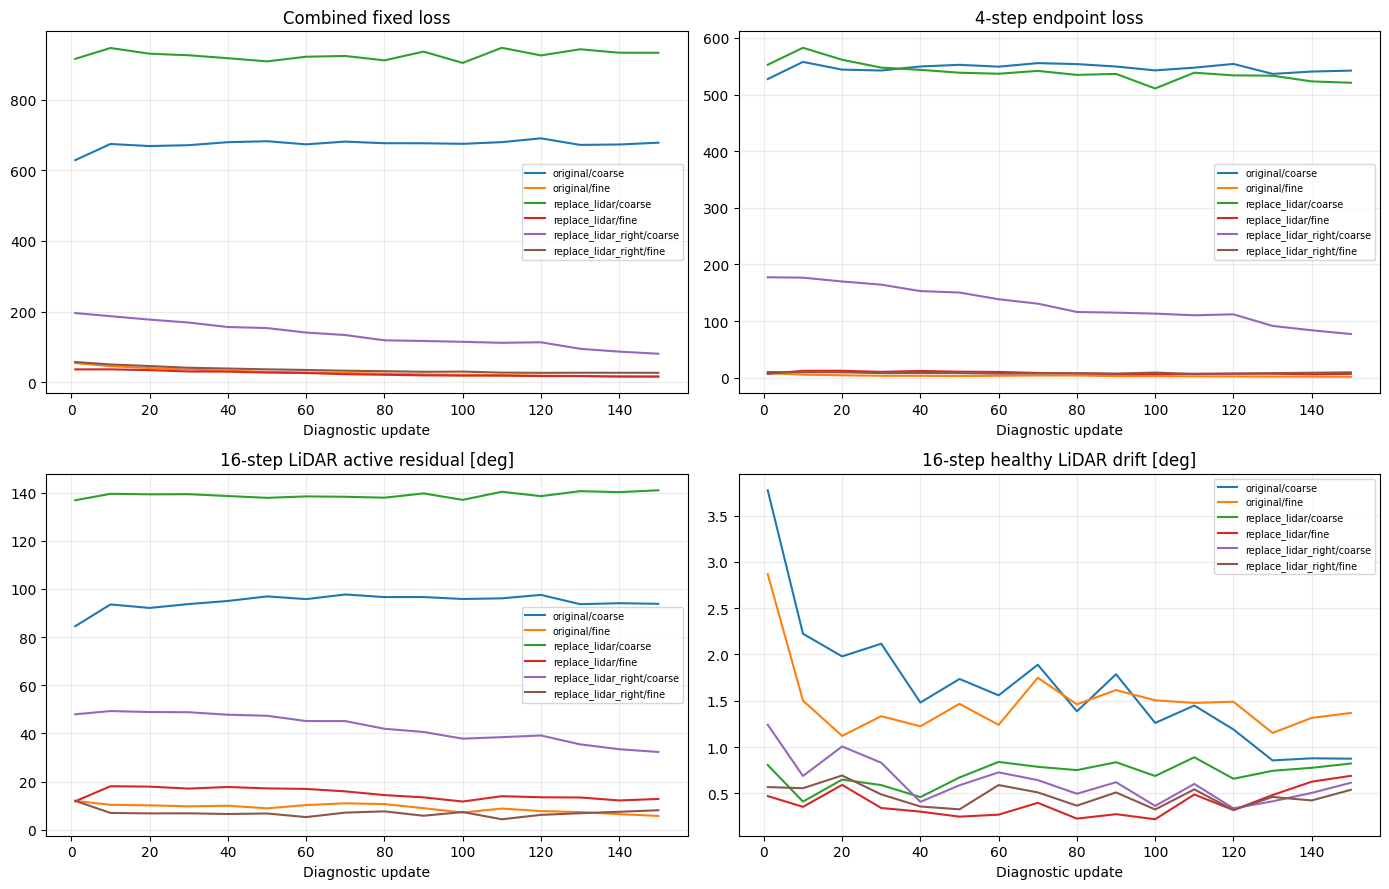

In [38]:
if precheck_history:
    check_df = pd.DataFrame(precheck_history)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for (mode, regime), part in check_df.groupby(["topology", "regime"]):
        line = f"{mode}/{regime}"
        axes[0, 0].plot(part.step, part.loss_combined_total, label=line)
        axes[0, 1].plot(part.step, part.loss_endpoint_total, label=line)
        if np.isfinite(part.inference_lidar_active_deg).any():
            axes[1, 0].plot(part.step, part.inference_lidar_active_deg, label=line)
        if np.isfinite(part.inference_lidar_healthy_deg).any():
            axes[1, 1].plot(part.step, part.inference_lidar_healthy_deg, label=line)
    for ax, title in zip(axes.flat, ("Combined fixed loss", "4-step endpoint loss", "16-step LiDAR active residual [deg]", "16-step healthy LiDAR drift [deg]")):
        ax.set(title=title, xlabel="Diagnostic update"); ax.grid(alpha=.25); ax.legend(fontsize=7)
    fig.tight_layout(); plt.show()
else:
    print("No stochastic-check history available")

## 12. Separate FM48 checkpointing, logging and optional exact resume


In [39]:
experiment_metadata = {
    "run_name": RUN_NAME, "source_fm_checkpoint": str(SOURCE_FM_CHECKPOINT), "source_regression_checkpoint": str(SOURCE_REGRESSION_CHECKPOINT),
    "architecture": "PooledCalibrationFlowModel", "backbone_config": model_config, "flow_config": flow_config,
    "training_loss": "right_composed_correction_to_go_velocity_plus_endpoint", "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS, "flow_path_points": FLOW_PATH_NUM_POINTS, "train_integration_steps": TRAIN_INTEGRATION_STEPS, "train_integration_method": TRAIN_INTEGRATION_METHOD, "velocity_loss_weight": VELOCITY_LOSS_WEIGHT, "endpoint_loss_weight": ENDPOINT_LOSS_WEIGHT, "flow_path_num_points": FLOW_PATH_NUM_POINTS, "full_objective": FULL_OBJECTIVE, "stochastic_objective": STOCHASTIC_OBJECTIVE, "flow_path_grid": "stratified times below max_time, deterministic validation", "true_calibration_config": true_calibration_config,
    "fine_prior_config": fine_prior_config, "coarse_prior_config": coarse_prior_config, "fine_probability": FINE_PRIOR_PROBABILITY,
    "topology_modes": TOPOLOGY_MODES, "topology_probabilities": TOPOLOGY_PROBABILITIES, "fault_key_weights": FAULT_KEY_WEIGHTS,
    "topology_configs": {mode: physical_augmenters[mode].config.sensor_topology for mode in TOPOLOGY_MODES},
    "common_frame_enabled": False, "data_splits": {"train": TRAIN_NAMES, "validation": VAL_NAMES, "test": TEST_NAMES},
}
history = []
start_epoch, global_step, best_validation_loss = 0, 0, float("inf")

RESUME_48_FROM_LAST = False
if RESUME_48_FROM_LAST:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    load_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, map_location=DEVICE, restore_rng_state=True)
    # Only load trusted checkpoint files made by this repository.
    resume_data = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    start_epoch = int(resume_data["epoch"])
    global_step = int(resume_data["global_step"])
    best_validation_loss = float(resume_data["extra_state"]["best_validation_loss"])
    history_path = RUN_DIR / "fm48_correction_to_go_history.csv"
    if history_path.is_file():
        history = pd.read_csv(history_path).to_dict("records")
        history = [row for row in history if int(row["epoch"]) <= start_epoch]
    if len(optimizer.param_groups) != 2 or fm_model.feature_extractor_frozen:
        raise RuntimeError("Resume expects two fully trainable FM optimizer groups")
    print("Resumed 48 from completed epoch", start_epoch, "steps", global_step)
else:
    print("Fresh correction-to-go optimizer initialized from source checkpoint weights; no source optimizer loaded.")


Fresh correction-to-go optimizer initialized from source checkpoint weights; no source optimizer loaded.


In [40]:
model_ids = {id(p) for p in fm_model.parameters() if p.requires_grad}
optimizer_ids = {id(p) for group in optimizer.param_groups for p in group["params"]}

assert model_ids == optimizer_ids, "Optimizer references a different model!"
print("Optimizer and model parameters match.")

Optimizer and model parameters match.


## 13. Full training (disabled until stochastic preflight supports it)


In [41]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [42]:
if RUN_FULL_TRAINING:
    if REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING and STOCHASTIC_CHECK_PASSED is not True:
        raise RuntimeError("The stochastic precheck has not passed. Review the per-topology fine/coarse curves or opt out explicitly.")
    for epoch in range(start_epoch, TRAIN_EPOCHS):
        train_shuffle_generator.manual_seed(SEED + 12001 + epoch)
        train_metrics = run_topology_fm_epoch(train_loader, training=True, seed=TRAIN_AUG_SEED + 100003 * epoch, topology=FULL_TRAIN_TOPOLOGY, regime=FULL_TRAIN_REGIME, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val_metrics = run_topology_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED, topology=FULL_TRAIN_TOPOLOGY, regime=FULL_TRAIN_REGIME, max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        mode_metrics = {}
        for mode_idx, mode in enumerate(TOPOLOGY_MODES):
            for regime_idx, regime in enumerate(("fine", "coarse")):
                result = run_topology_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED + 101 * mode_idx + regime_idx + 2000, topology=mode, regime=regime, max_batches=REGIME_VALIDATION_BATCHES)
                mode_metrics[f"{mode}/{regime}"] = result["loss_combined_total"]
        scheduler.step(val_metrics["loss_combined_total"])
        global_step += train_metrics["optimizer_steps"]
        row = {"epoch": epoch + 1, "train_loss": train_metrics["loss_combined_total"], "val_loss": val_metrics["loss_combined_total"], "train_velocity": train_metrics["loss_fm_total"], "val_velocity": val_metrics["loss_fm_total"], "train_endpoint": train_metrics["loss_endpoint_total"], "val_endpoint": val_metrics["loss_endpoint_total"], "train_seconds": train_metrics["seconds"], "optimizer_steps": train_metrics["optimizer_steps"], **{f"val_{mode}_{regime}": value for (mode, regime), value in ((key.split("/"), val) for key, val in mode_metrics.items())}}
        for mode in TOPOLOGY_MODES:
            row[f"train_topology_n_{mode}"] = train_metrics[f"topology_n/{mode}"]
        history.append(row)
        improved = val_metrics["loss_combined_total"] < best_validation_loss
        if improved:
            best_validation_loss = val_metrics["loss_combined_total"]
            save_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
        save_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch+1, global_step=global_step, metrics=val_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
        pd.DataFrame(history).to_csv(RUN_DIR / "fm48_correction_to_go_history.csv", index=False)
        print(f"Epoch {epoch+1:3d}/{TRAIN_EPOCHS} train={train_metrics['loss_combined_total']:.4f} val={val_metrics['loss_combined_total']:.4f} " + " ".join(f"{mode}({mode_metrics[mode+'/fine']:.3f}/{mode_metrics[mode+'/coarse']:.3f})" for mode in TOPOLOGY_MODES) + f" | LRs={optimizer.param_groups[0]['lr']:.1e}/{optimizer.param_groups[1]['lr']:.1e}" + (" BEST" if improved else ""), flush=True)
    if BEST_CHECKPOINT_PATH.is_file():
        load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
        print("Best FM48 checkpoint selected:", BEST_CHECKPOINT_PATH)
else:
    print("Full training skipped. The loaded model stays at the source checkpoint unless RESUME_46_FROM_LAST=True.")
fm_model.eval()


Epoch   1/200 train=21.5077 val=21.3939 original(16.364/390.370) replace_lidar(29.352/352.908) replace_lidar_right(23.946/701.315) | LRs=5.0e-05/5.0e-06 BEST
Epoch   2/200 train=18.3691 val=17.8453 original(13.881/395.659) replace_lidar(26.504/350.960) replace_lidar_right(20.698/703.094) | LRs=5.0e-05/5.0e-06 BEST
Epoch   3/200 train=17.3952 val=15.5004 original(13.413/390.108) replace_lidar(24.398/345.284) replace_lidar_right(20.273/703.749) | LRs=5.0e-05/5.0e-06 BEST
Epoch   4/200 train=14.9842 val=13.6856 original(12.858/392.885) replace_lidar(23.487/343.766) replace_lidar_right(18.507/702.660) | LRs=5.0e-05/5.0e-06 BEST
Epoch   5/200 train=13.6479 val=12.3052 original(11.193/386.829) replace_lidar(22.451/341.580) replace_lidar_right(17.026/705.195) | LRs=5.0e-05/5.0e-06 BEST
Epoch   6/200 train=12.3433 val=11.1063 original(10.421/391.496) replace_lidar(21.896/340.438) replace_lidar_right(16.438/706.324) | LRs=5.0e-05/5.0e-06 BEST
Epoch   7/200 train=11.7967 val=10.1910 original(9.9

KeyboardInterrupt: 

## 14. Training and topology-specific validation plots

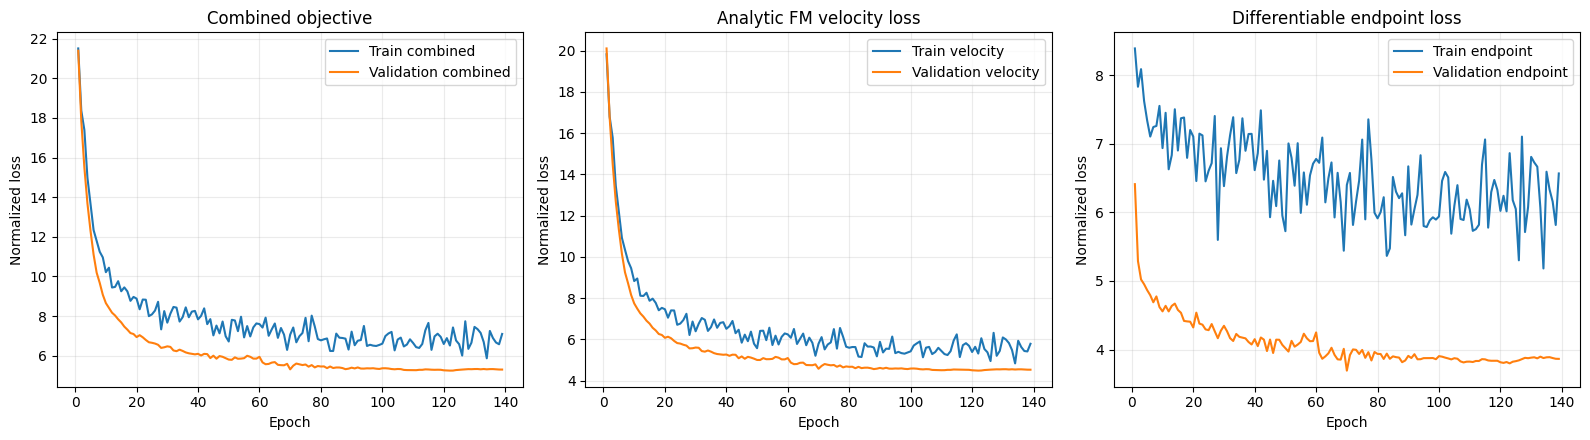

In [43]:
if not history and (RUN_DIR / "fm48_correction_to_go_history.csv").is_file():
    history = pd.read_csv(RUN_DIR / "fm48_correction_to_go_history.csv").to_dict("records")
if history:
    hdf = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(hdf.epoch, hdf.train_loss, label="Train combined")
    axes[0].plot(hdf.epoch, hdf.val_loss, label="Validation combined")
    axes[1].plot(hdf.epoch, hdf.train_velocity, label="Train velocity")
    axes[1].plot(hdf.epoch, hdf.val_velocity, label="Validation velocity")
    axes[2].plot(hdf.epoch, hdf.train_endpoint, label="Train endpoint")
    axes[2].plot(hdf.epoch, hdf.val_endpoint, label="Validation endpoint")
    for ax, title in zip(axes, ("Combined objective", "Analytic FM velocity loss", "Differentiable endpoint loss")):
        ax.set(title=title, xlabel="Epoch", ylabel="Normalized loss"); ax.grid(alpha=.25); ax.legend()
    fig.tight_layout(); plt.show()
else:
    print("No training history yet")


## 15. Paired held-out comparison (disabled until an FM48 checkpoint is selected)

Compare the FM48 correction-to-go model, the unchanged FM .4 source, and regression 2.24 on identical held-out augmented physical windows. Do not tune solver settings or augmentation hyperparameters on test sequences.


In [44]:
def sampled_indices_by_sequence(dataset, names, per_sequence: int):
    chosen = []
    for sequence in names:
        indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=int)
        if len(indices):
            positions = np.unique(np.linspace(0, len(indices)-1, min(per_sequence, len(indices))).round().astype(int))
            chosen.extend([(sequence, int(indices[i])) for i in positions])
    return chosen

@torch.no_grad()
def paired_topology_evaluation_cases(dataset, names, *, windows_per_sequence=EVAL_WINDOWS_PER_SEQUENCE):
    result = []
    for mode_idx, mode in enumerate(TOPOLOGY_MODES):
        for regime_idx, regime in enumerate(("fine", "coarse")):
            generator = augmentation_generator(TEST_AUG_SEED + 3333 + 100 * mode_idx + regime_idx)
            for sequence, index in sampled_indices_by_sequence(dataset, names, windows_per_sequence):
                base = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
                augmented = augment_topology_window(base, generator, topology=mode, regime=regime)
                tokens, context = tokenize_window(augmented)
                result.append({"sequence": sequence, "index": index, "topology": mode, "regime": regime, "window": augmented, "tokens": tokens, "context": context})
    return result

@torch.no_grad()
def evaluate_paired_model(model, cases, model_name, *, steps=FM_INTEGRATION_STEPS):
    model.eval()
    rows = []
    for case in cases:
        if isinstance(model, PooledCalibrationFlowModel):
            predictions = model(case["tokens"], case["context"], num_steps=steps, method=FM_INTEGRATION_METHOD).predictions
        else:
            predictions = model(case["tokens"], case["context"]).predictions
        xi_truth, tau_truth = correction_targets(case["window"])
        for key, pred in predictions.items():
            current = case["window"].current_calibration[key]
            true = case["window"].targets[key]
            corrected = se3_exp(pred.delta_xi) @ current.transform
            rot0 = torch.rad2deg(torch.linalg.vector_norm(xi_truth[key][:, :3], dim=-1))
            rot1 = torch.rad2deg(torch.linalg.vector_norm(se3_log(true.next_transform @ torch.linalg.inv(corrected))[:, :3], dim=-1))
            trans1 = 100.0 * torch.linalg.vector_norm(corrected[:, :3, 3] - true.next_transform[:, :3, 3], dim=-1)
            tau1 = 1000.0 * torch.abs(current.time_offset + pred.delta_tau - true.next_time_offset).reshape(-1)
            is_active = (torch.linalg.vector_norm(xi_truth[key][:, :3], dim=-1) > 1e-5) | (tau_truth[key].reshape(-1).abs() > 1e-6)
            for i in range(len(rot0)):
                rows.append({"model": model_name, "sequence": case["sequence"], "index": case["index"], "topology": case["topology"], "regime": case["regime"], "key": key,
                             "initial_rotation_deg": rot0[i].item(), "rotation_error_deg": rot1[i].item(), "translation_error_cm": trans1[i].item(), "tau_error_ms": tau1[i].item(), "active_fault": bool(is_active[i].item())})
    return pd.DataFrame(rows)

if RUN_FINAL_EVALUATION:
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Train notebook 48 first; no best checkpoint found: {BEST_CHECKPOINT_PATH}")
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
    fm_model.eval()
    evaluation_cases = paired_topology_evaluation_cases(test_dataset, TEST_NAMES)
    predictions_48 = evaluate_paired_model(fm_model, evaluation_cases, "FM 48")
    # Evaluate controls sequentially so GPU does not need to hold three models together.
    source_fm_control = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
    load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=source_fm_control, map_location=DEVICE, restore_rng_state=False)
    source_fm_control.eval().requires_grad_(False)
    predictions_source = evaluate_paired_model(source_fm_control, evaluation_cases, "FM source")
    del source_fm_control
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    if SOURCE_REGRESSION_CHECKPOINT.is_file():
        regression_control = PooledCalibrationModel(model_config).to(DEVICE, dtype=DTYPE)
        load_training_checkpoint(SOURCE_REGRESSION_CHECKPOINT, model=regression_control, map_location=DEVICE, restore_rng_state=False)
        regression_control.eval().requires_grad_(False)
        predictions_regression = evaluate_paired_model(regression_control, evaluation_cases, "Regression 2.24")
        del regression_control
    else:
        predictions_regression = pd.DataFrame()
        print("Regression checkpoint missing; compared source FM and FM48 only.")
    evaluation_df = pd.concat([predictions_48, predictions_source, predictions_regression], ignore_index=True)
    evaluation_df.to_csv(RUN_DIR / "fm48_correction_to_go_paired_test.csv", index=False)
    display(evaluation_df.groupby(["topology", "regime", "model"])[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]].mean().round(3))
    display(evaluation_df[evaluation_df.active_fault].groupby(["topology", "model"])[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]].agg(["mean", "median"]).round(3))
    display(evaluation_df[~evaluation_df.active_fault].groupby(["topology", "model"])[["rotation_error_deg", "tau_error_ms"]].mean().round(3))
else:
    print("Final test evaluation disabled; select a trained checkpoint first.")


rotation_error_deg  \
topology            regime model                                 
original            coarse FM 48                        14.793   
                           FM source                    12.746   
                           Regression 2.24              18.719   
                    fine   FM 48                         1.435   
                           FM source                     2.863   
                           Regression 2.24               1.170   
replace_lidar       coarse FM 48                        29.968   
                           FM source                    26.099   
                           Regression 2.24              27.721   
                    fine   FM 48                         3.418   
                           FM source                     5.089   
                           Regression 2.24               2.415   
replace_lidar_right coarse FM 48                        32.134   
                           FM source                    26.405   
                           Regression 2.24              53.449   
                    fine   FM 48                         4.156   
                           FM source                     4.586   
                           Regression 2.24               3.753   

                                            translation_error_cm  tau_error_ms  
topology            regime model                                                
original            coarse FM 48                          36.266        27.370  
                           FM source                      30.923        19.508  
                           Regression 2.24                42.250        12.503  
                    fine   FM 48                           4.447         4.710  
                           FM source                       8.605         9.491  
                           Regression 2.24                 3.529         7.579  
replace_lidar       coarse FM 48                          53.569        30.153  
                           FM source                      51.353        12.104  
                           Regression 2.24                49.292        33.304  
                    fine   FM 48                           4.131         9.754  
                           FM source                       9.272         9.871  
                           Regression 2.24                 3.446         8.644  
replace_lidar_right coarse FM 48                          76.244        73.089  
                           FM source                      56.465        50.846  
                           Regression 2.24               124.079       103.928  
                    fine   FM 48                          10.635        17.439  
                           FM source                      12.085         9.406  
                           Regression 2.24                 9.258        11.840

rotation_error_deg          \
                                                  mean  median   
topology            model                                        
original            FM 48                       24.083   4.219   
                    FM source                   22.431  10.498   
                    Regression 2.24             29.110   3.985   
replace_lidar       FM 48                       45.564  13.832   
                    FM source                   45.832  11.901   
                    Regression 2.24             42.721  13.320   
replace_lidar_right FM 48                       51.360  30.743   
                    FM source                   44.350  26.949   
                    Regression 2.24             65.782  26.760   

                                    translation_error_cm           \
                                                    mean   median   
topology            model                                           
original            FM 48                         60.378   10.180   
                    FM source                     56.242   23.840   
                    Regression 2.24               66.223    8.632   
replace_lidar       FM 48                         77.568    9.844   
                    FM source                     88.494   29.901   
                    Regression 2.24               73.277   12.704   
replace_lidar_right FM 48                        123.756  102.832   
                    FM source                     96.607   83.645   
                    Regression 2.24              154.226   89.658   

                                    tau_error_ms          
                                            mean  median  
topology            model                                 
original            FM 48                 45.495  20.925  
                    FM source             40.976  18.257  
                    Regression 2.24       23.943   7.820  
replace_lidar       FM 48                 40.737  24.244  
                    FM source             28.361  26.173  
                    Regression 2.24       48.907  51.522  
replace_lidar_right FM 48                116.994  61.606  
                    FM source             82.385  29.186  
                    Regression 2.24       80.855  39.968

rotation_error_deg  tau_error_ms
topology            model                                            
original            FM 48                         0.129         1.312
                    FM source                     0.491         1.261
                    Regression 2.24               0.362         3.090
replace_lidar       FM 48                         2.257         9.562
                    FM source                     0.475         2.301
                    Regression 2.24               1.242         7.007
replace_lidar_right FM 48                         1.537         9.399
                    FM source                     1.068         3.996
                    Regression 2.24              10.011        46.398

## 16. Optional topology-specific error plots and 4–32-step ablation

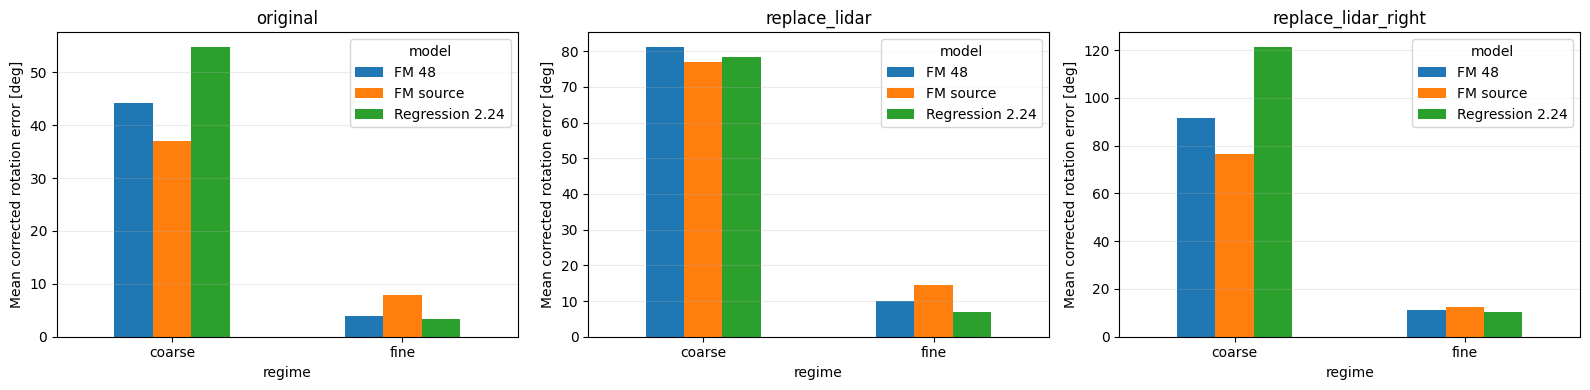

,steps,topology,rotation_mean_deg,tau_mean_ms
0,1,original,31.714,50.003
1,1,replace_lidar,29.571,40.837
2,1,replace_lidar_right,58.969,121.869
3,2,original,32.098,52.102
4,2,replace_lidar,30.058,44.534
5,2,replace_lidar_right,59.663,121.859
6,4,original,32.089,52.409
7,4,replace_lidar,30.138,45.345
8,4,replace_lidar_right,59.719,121.371
9,8,original,32.069,52.556


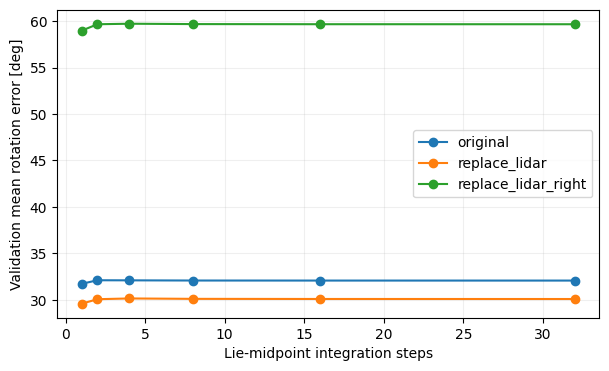

In [45]:
if RUN_FINAL_EVALUATION:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, mode in zip(axes, TOPOLOGY_MODES):
        subset = evaluation_df[(evaluation_df.topology == mode) & (evaluation_df.active_fault)]
        if not subset.empty:
            summary = subset.groupby(["regime", "model"])["rotation_error_deg"].mean().unstack("model")
            summary.plot.bar(ax=ax, rot=0)
        ax.set(title=mode, ylabel="Mean corrected rotation error [deg]")
        ax.grid(axis="y", alpha=.25)
    fig.tight_layout()
    fig.savefig(RUN_DIR / "fm48_topology_paired_rotation.png", dpi=160, bbox_inches="tight")
    plt.show()

if RUN_FINAL_EVALUATION and RUN_INTEGRATION_ABLATION:
    # Must not use test results to tune the integration steps: these are VAL cases.
    validation_cases = paired_topology_evaluation_cases(val_dataset, VAL_NAMES, windows_per_sequence=2)
    step_rows = []
    for steps in ABLATION_STEPS:
        dataframe = evaluate_paired_model(fm_model, validation_cases, "FM 48", steps=steps)
        for mode, group in dataframe[dataframe.active_fault].groupby("topology"):
            step_rows.append({"steps": steps, "topology": mode, "rotation_mean_deg": group.rotation_error_deg.mean(), "tau_mean_ms": group.tau_error_ms.mean()})
    step_df = pd.DataFrame(step_rows)
    display(step_df.round(3))
    step_df.to_csv(RUN_DIR / "fm48_validation_steps.csv", index=False)
    fig, ax = plt.subplots(figsize=(7, 4))
    for mode, frame in step_df.groupby("topology"):
        ax.plot(frame.steps, frame.rotation_mean_deg, "-o", label=mode)
    ax.set(xlabel="Lie-midpoint integration steps", ylabel="Validation mean rotation error [deg]")
    ax.legend(); ax.grid(alpha=.2)
    plt.show()


## 17. Interpretation and next experiments

The central comparison is **integrator robustness**: check whether correction-to-go training makes 2, 4, 8 and 16-step inference agree more closely, and whether LiDAR recovery improves without sacrificing healthy-state stability or small-angle accuracy.

Begin with `STOCHASTIC_TRAIN_TOPOLOGY="replace_lidar_right"`, `STOCHASTIC_TRAIN_REGIME="fine"`. Then change only `STOCHASTIC_TRAIN_TOPOLOGY="mixture"` and `STOCHASTIC_TRAIN_REGIME="mixed"` to test cross-topology learning. The stochastic preflight restores model weights and RNG; do not treat it as a full-dataset convergence guarantee.

If correction-to-go still underperforms, compare target sampling `on_path` versus `mixed`, reduced off-path noise, and velocity-only versus velocity-plus-endpoint objectives. Those are individually controlled experiments, not extra changes silently applied here.


In [46]:
# Diagnostic configuration and fixed validation cases. Run after the model has been loaded.
# Does not update the model, optimizer, scheduler, or checkpoints.

DIAG_TOPOLOGY = "original"  # Change to "replace_lidar" or "replace_lidar_right" later.
DIAG_REGIMES = ("fine", "coarse")
DIAG_SEED = VAL_AUG_SEED + 840000
DIAG_WINDOWS = min(24, len(val_dataset))
DIAG_BATCH_SIZE = min(BATCH_SIZE, 8)
DIAG_SOLVER_STEPS = 16  # Midpoint; time samples are exact multiples of 1/16.
DIAG_TIME_INDICES = (0, 1, 2, 4, 8, 12, 14, 15)  # No t=1 singularity.
DIAG_TIMES = tuple(i / DIAG_SOLVER_STEPS for i in DIAG_TIME_INDICES)

assert DIAG_TOPOLOGY in TOPOLOGY_MODES
assert DIAG_BATCH_SIZE >= 2, "Feature-shuffling diagnostic requires at least two windows."
assert max(DIAG_TIMES) < 1.0

selected_indices = np.unique(np.linspace(0, len(val_dataset) - 1, DIAG_WINDOWS).astype(int))
diag_cases = {}  # (minibatch_index, regime) -> CPU WindowBatch
for batch_index, offset in enumerate(range(0, len(selected_indices), DIAG_BATCH_SIZE)):
    indices = selected_indices[offset:offset + DIAG_BATCH_SIZE]
    if len(indices) < 2:
        continue  # Shuffling needs >= 2 physical windows.
    base = window_batch_to(collate_windows([val_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
    for regime_index, regime in enumerate(DIAG_REGIMES):
        generator = augmentation_generator(DIAG_SEED + 1000 * batch_index + 10 * regime_index)
        with torch.no_grad():
            augmented = augment_topology_window(base, generator, topology=DIAG_TOPOLOGY, regime=regime)
        diag_cases[(batch_index, regime)] = window_batch_to(augmented, torch.device("cpu"), dtype=DTYPE)
    del base

if not diag_cases:
    raise RuntimeError("No diagnostic cases generated")


def diag_tensor_case(cpu_window):
    """Encode only once, with identical ordering for targets and pooled features."""
    window = window_batch_to(cpu_window, DEVICE, dtype=DTYPE)
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
        shared, stacked_context = fm_model.encode_calibration_features(tokens, context)
        keys = tuple(tokens.calibration_keys)
        delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
        delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)
        b, c, _ = delta_xi.shape
        goal = se3_exp(delta_xi.reshape(-1, 6)).reshape(b, c, 4, 4)
        active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > 1e-6
    return window, keys, shared, stacked_context, delta_xi, delta_tau, goal, active


def diag_oracle_velocity(D, tau, t, goal, goal_tau):
    """Right-composed exact correction-to-go velocity at an arbitrary state, t < 1."""
    remaining = torch.linalg.solve(D, goal)
    b, c = goal.shape[:2]
    remaining_xi = se3_log(remaining.reshape(-1, 4, 4)).reshape(b, c, 6)
    return torch.cat((remaining_xi / (1.0 - t), (goal_tau - tau) / (1.0 - t)), dim=-1)


def diag_evaluate_velocity(shared, stacked_context, D, tau, t):
    b, c = D.shape[:2]
    current_xi = se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6)
    time = shared.new_full((b, c, 1), t)
    return fm_model.velocity_from_features(shared, current_xi, tau, time, stacked_context)


def diag_state_records(records, *, keys, regime, batch_index, source, t, velocity, target, active,
                       D=None, ideal_D=None):
    """Store per-sample physical velocity errors, not a topology-averaged loss."""
    residual = velocity - target
    rot_deg = torch.rad2deg(torch.linalg.vector_norm(residual[..., :3], dim=-1))
    trans_cm = 100.0 * torch.linalg.vector_norm(residual[..., 3:6], dim=-1)
    tau_ms = 1000.0 * residual[..., 6].abs()
    if D is not None and ideal_D is not None:
        delta = torch.linalg.solve(ideal_D, D)
        delta_xi = se3_log(delta.reshape(-1, 4, 4)).reshape(*D.shape[:2], 6)
        state_deviation_deg = torch.rad2deg(torch.linalg.vector_norm(delta_xi[..., :3], dim=-1))
    else:
        state_deviation_deg = torch.zeros_like(rot_deg)
    for index, key in enumerate(keys):
        for sample_index in range(rot_deg.shape[0]):
            records.append({
                "batch": batch_index, "sample": sample_index, "topology": DIAG_TOPOLOGY,
                "regime": regime, "key": key,
                "role": "active" if bool(active[sample_index, index]) else "healthy",
                "state_source": source, "time": float(t),
                "rotation_v_error_deg": float(rot_deg[sample_index, index]),
                "translation_v_error_cm": float(trans_cm[sample_index, index]),
                "tau_v_error_ms": float(tau_ms[sample_index, index]),
                "state_deviation_deg": float(state_deviation_deg[sample_index, index]),
            })

print(f"Diagnostic cases: {len(diag_cases)} | windows: {len(selected_indices)} | topology: {DIAG_TOPOLOGY}")
print("Flow times:", DIAG_TIMES)


Diagnostic cases: 6 | windows: 24 | topology: original
Flow times: (0.0, 0.0625, 0.125, 0.25, 0.5, 0.75, 0.875, 0.9375)


,regime,key,role,state_source,time,rotation_v_error_deg,translation_v_error_cm,tau_v_error_ms,state_deviation_deg
0,coarse,imu,active,model_rollout,0.000,42.856,0.170,15.935,0.000
4,coarse,imu,active,model_rollout,0.500,81.053,0.781,31.645,20.857
6,coarse,imu,active,model_rollout,0.875,324.642,4.035,168.072,35.772
8,coarse,imu,active,oracle_path,0.000,42.856,0.170,15.935,0.000
12,coarse,imu,active,oracle_path,0.500,33.658,0.827,22.878,0.000
14,coarse,imu,active,oracle_path,0.875,31.886,1.206,48.627,0.000
32,coarse,lidar,active,model_rollout,0.000,106.834,0.334,27.215,0.000
36,coarse,lidar,active,model_rollout,0.500,209.585,0.969,51.501,53.496
38,coarse,lidar,active,model_rollout,0.875,834.242,5.065,210.809,91.949
40,coarse,lidar,active,oracle_path,0.000,106.834,0.334,27.215,0.000


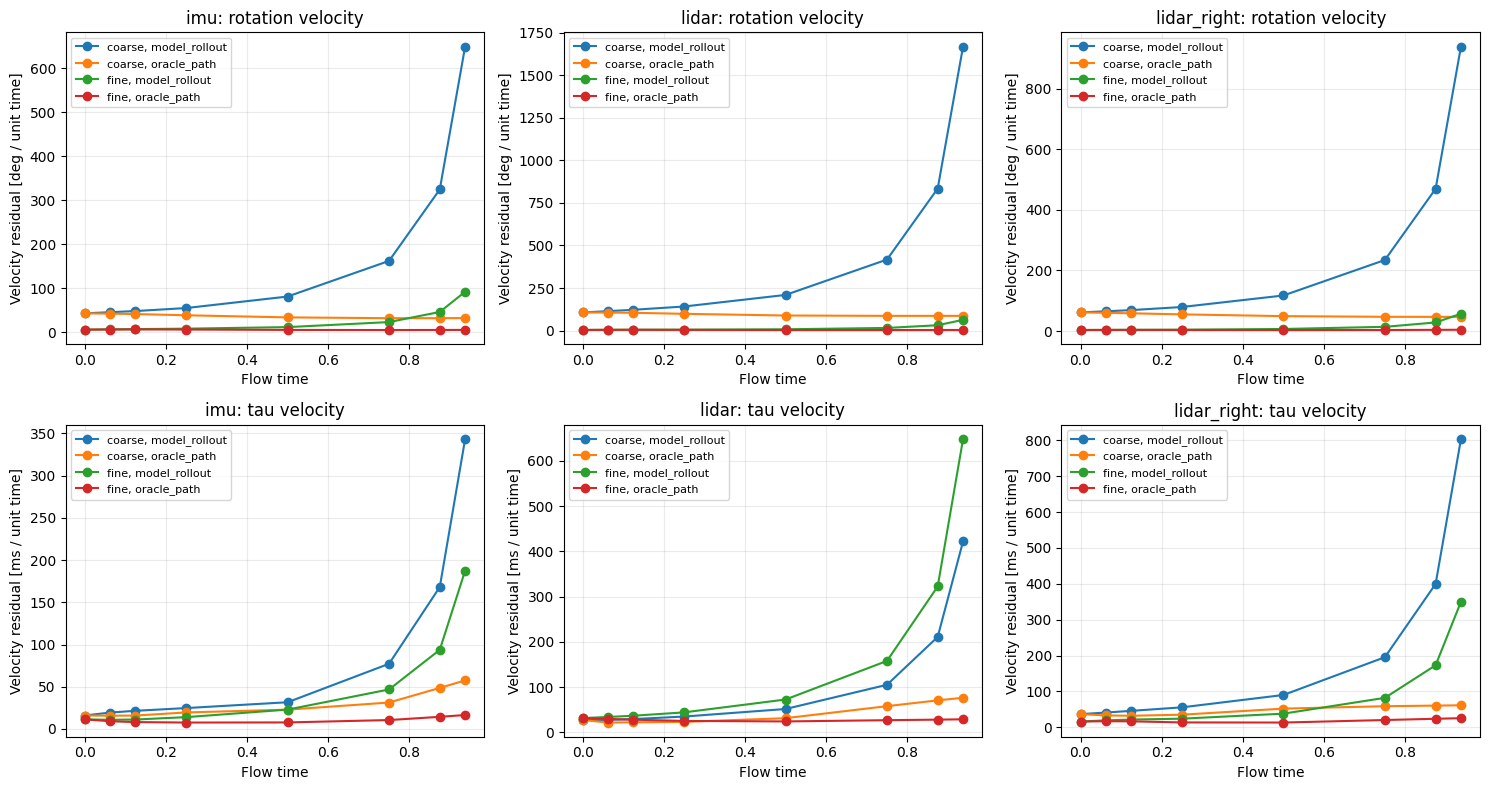

,regime,key,state_deviation_deg
0,coarse,imu,38.199
1,coarse,lidar,98.149
2,coarse,lidar_right,55.254
3,fine,imu,5.394
4,fine,lidar,3.718
5,fine,lidar_right,3.307


In [47]:
# A. Velocity accuracy along the oracle path versus the model's OWN trajectory.
# The target at every visited state is recalculated with Log(D^{-1} D*)/(1-t).

path_rows = []
saved_model_mode = fm_model.training
fm_model.eval()
try:
    with torch.inference_mode():
        for (batch_index, regime), cpu_case in diag_cases.items():
            _, keys, shared, stacked_context, delta_xi, delta_tau, goal, active = diag_tensor_case(cpu_case)
            trajectory = fm_model.integrate_from_features(
                shared, stacked_context, num_steps=DIAG_SOLVER_STEPS,
                method="midpoint", record_trajectory=True,
            ).trajectory
            assert trajectory is not None and len(trajectory) == DIAG_SOLVER_STEPS + 1
            for step_index, t in zip(DIAG_TIME_INDICES, DIAG_TIMES):
                b, c, _ = delta_xi.shape
                ideal_D = se3_exp((t * delta_xi).reshape(-1, 6)).reshape(b, c, 4, 4)
                ideal_tau = t * delta_tau
                rollout_D = trajectory[step_index].correction_transform
                rollout_tau = trajectory[step_index].correction_tau
                for source, D, tau in (("oracle_path", ideal_D, ideal_tau), ("model_rollout", rollout_D, rollout_tau)):
                    predicted = diag_evaluate_velocity(shared, stacked_context, D, tau, t)
                    oracle = diag_oracle_velocity(D, tau, t, goal, delta_tau)
                    diag_state_records(
                        path_rows, keys=keys, regime=regime, batch_index=batch_index,
                        source=source, t=t, velocity=predicted, target=oracle, active=active,
                        D=D, ideal_D=ideal_D,
                    )
finally:
    fm_model.train(saved_model_mode)

path_df = pd.DataFrame(path_rows)
path_summary = path_df.groupby(["regime", "key", "role", "state_source", "time"], as_index=False)[
    ["rotation_v_error_deg", "translation_v_error_cm", "tau_v_error_ms", "state_deviation_deg"]
].mean()

# Show the most relevant subset first, keeping fine/coarse and healthy/active separate.
display(path_summary[(path_summary.role == "active") & (path_summary.time.isin([0.0, 0.5, 0.875]))].round(3))

keys_in_plot = tuple(next(iter(diag_cases.values())).current_calibration)
fig, axes = plt.subplots(2, len(keys_in_plot), figsize=(5 * len(keys_in_plot), 8), squeeze=False)
for column, key in enumerate(keys_in_plot):
    for (regime, source), part in path_summary[(path_summary.key == key) & (path_summary.role == "active")].groupby(["regime", "state_source"]):
        part = part.sort_values("time")
        label = f"{regime}, {source}"
        axes[0, column].plot(part.time, part.rotation_v_error_deg, "-o", label=label)
        axes[1, column].plot(part.time, part.tau_v_error_ms, "-o", label=label)
    axes[0, column].set(title=f"{key}: rotation velocity", xlabel="Flow time", ylabel="Velocity residual [deg / unit time]")
    axes[1, column].set(title=f"{key}: tau velocity", xlabel="Flow time", ylabel="Velocity residual [ms / unit time]")
    for axis in axes[:, column]:
        axis.grid(alpha=0.25)
        axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

# This tells us whether model-generated states depart from the analytical path.
display(path_summary[(path_summary.state_source == "model_rollout") & (path_summary.role == "active")].groupby(
    ["regime", "key"], as_index=False
)[["state_deviation_deg"]].max().round(3))


,regime,key,role,state_source,time,base_rotation_v_error_deg,shuffled_rotation_v_error_deg,output_change_deg,error_increase_deg
0,coarse,imu,active,model_rollout,0.000,42.856,90.797,66.982,47.942
1,coarse,imu,active,model_rollout,0.500,81.053,138.252,82.999,57.199
2,coarse,imu,active,model_rollout,0.875,324.642,370.545,75.926,45.903
3,coarse,imu,active,oracle_path,0.000,42.856,90.797,66.982,47.942
4,coarse,imu,active,oracle_path,0.500,33.658,97.558,74.753,63.901
5,coarse,imu,active,oracle_path,0.875,31.886,88.436,65.783,56.550
12,coarse,lidar,active,model_rollout,0.000,106.834,122.420,54.183,15.586
13,coarse,lidar,active,model_rollout,0.500,209.585,233.045,71.461,23.460
14,coarse,lidar,active,model_rollout,0.875,834.242,855.533,70.237,21.291
15,coarse,lidar,active,oracle_path,0.000,106.834,122.420,54.183,15.586


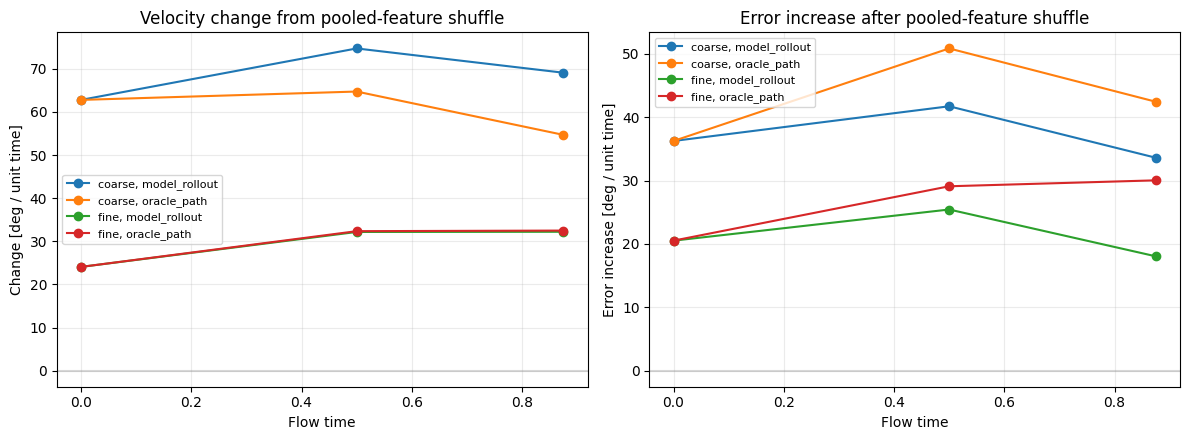

In [48]:
# B. Controlled feature-shuffle intervention.
# Swap only pooled features across physical windows. Keep the calibration context,
# correction state, target and time FIXED. This probes dependence on pooled features,
# but cannot isolate raw sensor tokens from any context already fused into them.

DIAG_SHUFFLE_TIMES = (0.0, 0.5, 0.875)
DIAG_SHUFFLE_SOURCES = ("oracle_path", "model_rollout")
shuffle_rows = []
saved_model_mode = fm_model.training
fm_model.eval()
try:
    with torch.inference_mode():
        for (batch_index, regime), cpu_case in diag_cases.items():
            _, keys, shared, stacked_context, delta_xi, delta_tau, goal, active = diag_tensor_case(cpu_case)
            if shared.shape[0] < 2:
                continue
            # Cyclic permutation ensures that no physical window keeps its own pooled features.
            swapped_shared = shared.roll(shifts=1, dims=0)
            trajectory = fm_model.integrate_from_features(
                shared, stacked_context, num_steps=DIAG_SOLVER_STEPS,
                method="midpoint", record_trajectory=True,
            ).trajectory
            b, c, _ = delta_xi.shape
            for t in DIAG_SHUFFLE_TIMES:
                index = int(round(t * DIAG_SOLVER_STEPS))
                ideal_D = se3_exp((t * delta_xi).reshape(-1, 6)).reshape(b, c, 4, 4)
                states = {
                    "oracle_path": (ideal_D, t * delta_tau),
                    "model_rollout": (trajectory[index].correction_transform, trajectory[index].correction_tau),
                }
                for source in DIAG_SHUFFLE_SOURCES:
                    D, tau = states[source]
                    oracle = diag_oracle_velocity(D, tau, t, goal, delta_tau)
                    original = diag_evaluate_velocity(shared, stacked_context, D, tau, t)
                    swapped = diag_evaluate_velocity(swapped_shared, stacked_context, D, tau, t)
                    base_error = torch.rad2deg(torch.linalg.vector_norm((original - oracle)[..., :3], dim=-1))
                    swap_error = torch.rad2deg(torch.linalg.vector_norm((swapped - oracle)[..., :3], dim=-1))
                    output_change = torch.rad2deg(torch.linalg.vector_norm((swapped - original)[..., :3], dim=-1))
                    for key_idx, key in enumerate(keys):
                        for sample_idx in range(b):
                            shuffle_rows.append({
                                "batch": batch_index, "regime": regime, "key": key, "time": t,
                                "role": "active" if bool(active[sample_idx, key_idx]) else "healthy",
                                "state_source": source,
                                "base_rotation_v_error_deg": float(base_error[sample_idx, key_idx]),
                                "shuffled_rotation_v_error_deg": float(swap_error[sample_idx, key_idx]),
                                "output_change_deg": float(output_change[sample_idx, key_idx]),
                            })
finally:
    fm_model.train(saved_model_mode)

shuffle_df = pd.DataFrame(shuffle_rows)
shuffle_summary = shuffle_df.groupby(
    ["regime", "key", "role", "state_source", "time"], as_index=False
)[["base_rotation_v_error_deg", "shuffled_rotation_v_error_deg", "output_change_deg"]].mean()
shuffle_summary["error_increase_deg"] = (
    shuffle_summary.shuffled_rotation_v_error_deg - shuffle_summary.base_rotation_v_error_deg
)
display(shuffle_summary[shuffle_summary.role == "active"].round(3))

# A feature shortcut is plausible if oracle-path errors are small at later times,
# and swapping features there barely changes predictions, while t=0 is inaccurate.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (regime, source), part in shuffle_summary[shuffle_summary.role == "active"].groupby(["regime", "state_source"]):
    series = part.groupby("time", as_index=False)[["output_change_deg", "error_increase_deg"]].mean()
    label = f"{regime}, {source}"
    axes[0].plot(series.time, series.output_change_deg, "-o", label=label)
    axes[1].plot(series.time, series.error_increase_deg, "-o", label=label)
axes[0].set(title="Velocity change from pooled-feature shuffle", xlabel="Flow time", ylabel="Change [deg / unit time]")
axes[1].set(title="Error increase after pooled-feature shuffle", xlabel="Flow time", ylabel="Error increase [deg / unit time]")
for axis in axes:
    axis.axhline(0, color="gray", alpha=0.3)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()


,batch,regime,combined_loss,velocity_loss,endpoint_loss
0,0,fine,1.801,1.578,1.114
1,0,coarse,582.431,492.110,451.602
2,1,fine,2.784,2.509,1.375
3,1,coarse,434.660,360.174,372.432


,objective,block,fine_norm,coarse_norm,coarse_over_fine,cosine,fine_weighted_norm,coarse_weighted_norm
0,combined,head,25.016,781.520,31.639,0.213,10.006,468.912
1,combined,mlp_body,15.534,515.274,34.103,0.320,6.214,309.165
2,combined,pooler,13.472,311.359,23.120,0.389,5.389,186.816
3,combined,transformer_encoder,113.695,1234.209,11.670,-0.296,45.478,740.525
4,endpoint_weighted,head,7.085,171.499,24.212,0.166,2.834,102.899
5,endpoint_weighted,mlp_body,4.351,115.131,26.801,0.292,1.740,69.079
6,endpoint_weighted,pooler,3.837,63.423,16.479,0.293,1.535,38.054
7,endpoint_weighted,transformer_encoder,35.916,241.259,7.177,-0.386,14.367,144.756
8,velocity_weighted,head,18.549,639.456,35.361,0.208,7.420,383.673
9,velocity_weighted,mlp_body,11.569,423.801,38.071,0.304,4.628,254.281


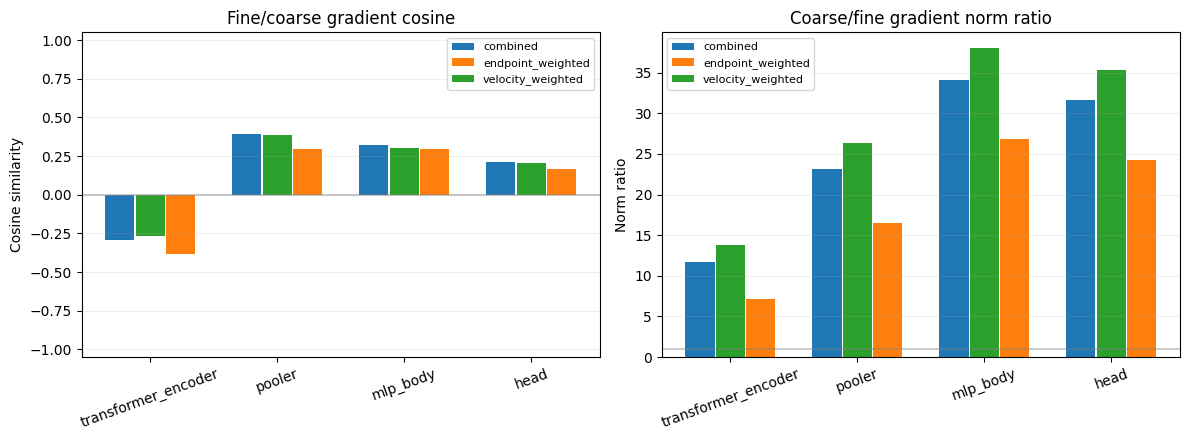

Negative cosine: conflicting directions. Large coarse/fine norm ratio: coarse dominates before regime weighting.
Interpret jointly: near-zero cosine is NOT evidence of conflict, and large loss values do not imply large gradients.


In [49]:
# C. Fine-vs-coarse gradient alignment, including losses' actual coefficients.
# Uses eval() to disable dropout and fixed time grids, but autograd remains ENABLED.
# autograd.grad does not populate p.grad or touch your optimizer state.

DIAG_GRAD_BATCHES = 2  # Can increase to 3 after the first successful run.
DIAG_GRAD_OBJECTIVES = ("combined", "velocity_weighted", "endpoint_weighted")

parameter_blocks = {
    "transformer_encoder": tuple(p for p in fm_model.transformer_encoder.parameters() if p.requires_grad),
    "pooler": tuple(p for p in fm_model.pooler.parameters() if p.requires_grad),
    "mlp_body": tuple(p for p in fm_model.mlp_body.parameters() if p.requires_grad),
    "head": tuple(p for p in fm_model.head.parameters() if p.requires_grad),
}
all_parameters = tuple(p for params in parameter_blocks.values() for p in params)
assert len({id(p) for p in all_parameters}) == len(all_parameters)

def diag_gradients_by_block(losses, objective):
    values = {
        "combined": losses.total,
        "velocity_weighted": FULL_OBJECTIVE["velocity_weight"] * losses.velocity.total,
        "endpoint_weighted": FULL_OBJECTIVE["endpoint_weight"] * losses.endpoint,
    }
    outputs = {}
    for objective_index, name in enumerate(objective):
        gradients = torch.autograd.grad(
            values[name], all_parameters,
            retain_graph=objective_index < len(objective) - 1,
            allow_unused=True,
        )
        cursor = 0
        for block_name, params in parameter_blocks.items():
            these = gradients[cursor:cursor + len(params)]
            cursor += len(params)
            vector = torch.cat([
                (g.detach() if g is not None else torch.zeros_like(p)).reshape(-1).float().cpu()
                for p, g in zip(params, these)
            ])
            outputs[(name, block_name)] = vector
    return outputs

saved_model_mode = fm_model.training
fm_model.eval()
metric_rows, gradient_rows = [], []
try:
    for batch_index in range(min(DIAG_GRAD_BATCHES, len(selected_indices) // DIAG_BATCH_SIZE)):
        gradients_by_regime = {}
        for regime in DIAG_REGIMES:
            case_id = (batch_index, regime)
            if case_id not in diag_cases:
                continue
            window = window_batch_to(diag_cases[case_id], DEVICE, dtype=DTYPE)
            # Fixed seeds make this measurement reproducible; both regimes share the
            # same physical validation windows, but have independently drawn faults.
            with torch.enable_grad():
                losses, _ = joint_flow_endpoint_supervision(
                    window,
                    generator=augmentation_generator(DIAG_SEED + 300000 + 1000 * batch_index + (0 if regime == "fine" else 1)),
                    model=fm_model,
                    objective=FULL_OBJECTIVE,
                )
                gradients_by_regime[regime] = diag_gradients_by_block(losses, DIAG_GRAD_OBJECTIVES)
                metric_rows.append({
                    "batch": batch_index, "regime": regime,
                    "combined_loss": float(losses.total.detach()),
                    "velocity_loss": float(losses.velocity.total.detach()),
                    "endpoint_loss": float(losses.endpoint.detach()),
                })
            del losses
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        if not all(regime in gradients_by_regime for regime in ("fine", "coarse")):
            continue
        for objective in DIAG_GRAD_OBJECTIVES:
            for block_name in parameter_blocks:
                fine = gradients_by_regime["fine"][(objective, block_name)]
                coarse = gradients_by_regime["coarse"][(objective, block_name)]
                fine_norm = torch.linalg.vector_norm(fine).item()
                coarse_norm = torch.linalg.vector_norm(coarse).item()
                cosine = float(torch.dot(fine, coarse) / (fine.norm() * coarse.norm())) if fine_norm > 0 and coarse_norm > 0 else float("nan")
                gradient_rows.append({
                    "batch": batch_index, "objective": objective, "block": block_name,
                    "fine_norm": fine_norm, "coarse_norm": coarse_norm,
                    "coarse_over_fine": coarse_norm / max(fine_norm, 1e-12),
                    "cosine": cosine,
                    "fine_weighted_norm": FINE_PRIOR_PROBABILITY * fine_norm,
                    "coarse_weighted_norm": (1.0 - FINE_PRIOR_PROBABILITY) * coarse_norm,
                })
finally:
    fm_model.train(saved_model_mode)

metric_df = pd.DataFrame(metric_rows)
grad_df = pd.DataFrame(gradient_rows)
display(metric_df.round(3))
display(grad_df.groupby(["objective", "block"], as_index=False)[
    ["fine_norm", "coarse_norm", "coarse_over_fine", "cosine", "fine_weighted_norm", "coarse_weighted_norm"]
].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for objective, group in grad_df.groupby("objective"):
    part = group.groupby("block", as_index=False)[["cosine", "coarse_over_fine"]].mean()
    labels = tuple(parameter_blocks)
    positions = np.arange(len(labels))
    offsets = {"combined": -0.24, "velocity_weighted": 0, "endpoint_weighted": 0.24}
    offset = offsets[objective]
    axes[0].bar(positions + offset, [float(part.loc[part.block == name, "cosine"].iloc[0]) for name in labels], width=0.23, label=objective)
    axes[1].bar(positions + offset, [float(part.loc[part.block == name, "coarse_over_fine"].iloc[0]) for name in labels], width=0.23, label=objective)
for axis in axes:
    axis.set_xticks(np.arange(len(parameter_blocks)), list(parameter_blocks), rotation=20)
    axis.grid(axis="y", alpha=0.2)
    axis.legend(fontsize=8)
axes[0].axhline(0, color="gray", alpha=0.4)
axes[0].set(title="Fine/coarse gradient cosine", ylabel="Cosine similarity", ylim=(-1.05, 1.05))
axes[1].axhline(1, color="gray", alpha=0.4)
axes[1].set(title="Coarse/fine gradient norm ratio", ylabel="Norm ratio")
plt.tight_layout()
plt.show()

print("Negative cosine: conflicting directions. Large coarse/fine norm ratio: coarse dominates before regime weighting.")
print("Interpret jointly: near-zero cosine is NOT evidence of conflict, and large loss values do not imply large gradients.")
